<a href="https://colab.research.google.com/github/ggritvik/Agricultural-Route-Optimization-using-2-level-GA-with-kmeans-clustering/blob/main/Route_optimization_strategies_with_multiple_cases.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import random
from sys import maxsize
import matplotlib.cm as cm
import itertools
from collections import defaultdict
import matplotlib.pyplot as plt
from itertools import permutations
from scipy.sparse.csgraph import minimum_spanning_tree
from scipy.spatial import distance_matrix
import plotly.graph_objects as go

# SMALL DATASET


In [ ]:
small = pd.read_csv('small.csv', names=['A', 'B'], header=None)

In [ ]:
small.head()

,A,B
0,-0.935834,-1.771533
1,-9.326265,13.902797
2,-8.233092,14.873970
3,3.272331,3.961212
4,1.175829,-0.699877


In [ ]:
def print_best_route(best_path):
    plt.figure(figsize=(8,8))
    for i, index in enumerate(best_path):
        x, y = coordinates[index]
        plt.text(x, y, str(i+1), fontsize=12, color='black', ha='right', va='top')
    plt.plot([coordinates[i][0] for i in best_path], [coordinates[i][1] for i in best_path], 'ro-')
    plt.plot([coordinates[best_path[-1]][0], coordinates[best_path[0]][0]], [coordinates[best_path[-1]][1], coordinates[best_path[0]][1]], 'ro-')
    plt.title('Best Path for the Salesman')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.grid(True)
    plt.show()

In [ ]:
def distance(p1, p2):
    return ((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)**0.5

In [ ]:
def nearest_neighbor(coordinates):
    n = len(coordinates)
    unvisited = list(range(n))
    path = []

    current_city = unvisited.pop(0)
    path.append(current_city)

    while unvisited:
        nearest_city = min(unvisited, key=lambda city: distance(coordinates[current_city], coordinates[city]))
        path.append(nearest_city)
        unvisited.remove(nearest_city)
        current_city = nearest_city

    path.append(path[0])
    total_distance = sum(distance(coordinates[path[i]], coordinates[path[i + 1]]) for i in range(n))
    return path, total_distance

In [ ]:
%%time
coordinates = small[['A', 'B']].values.tolist()
best_path, min_distance = nearest_neighbor(coordinates)
print("Best path:", best_path)
print("Minimum distance:", min_distance)

Best path: [0, 19, 6, 9, 29, 22, 20, 28, 4, 13, 3, 7, 25, 15, 12, 24, 8, 17, 16, 21, 27, 10, 11, 14, 2, 23, 5, 18, 26, 1, 0]
Minimum distance: 66.79316375709949
CPU times: user 1.91 ms, sys: 0 ns, total: 1.91 ms
Wall time: 1.88 ms


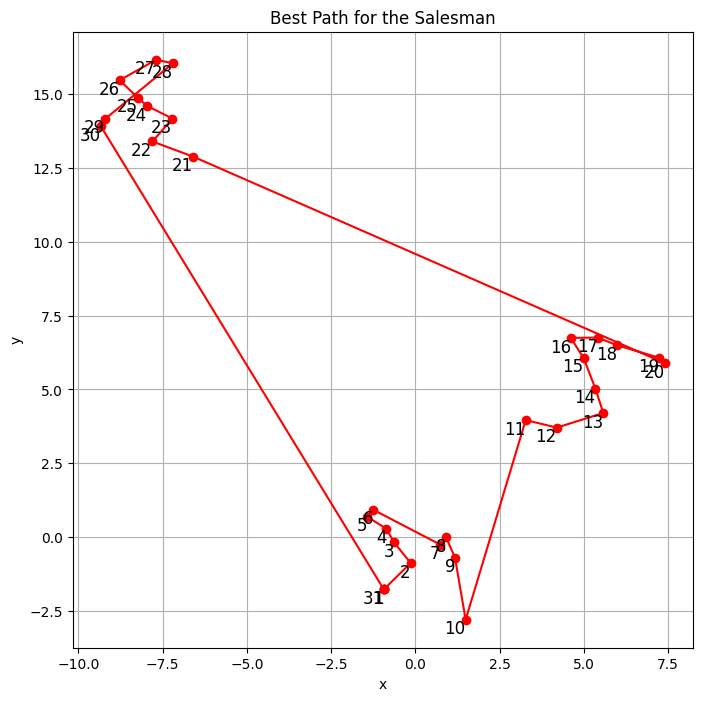

In [ ]:
print_best_route(best_path)

# MEDIUM DATASET

Epoch 1/5000, Best Distance: 44.265672548675354
Epoch 2/5000, Best Distance: 43.563754802715394
Epoch 5/5000, Best Distance: 40.977359205578765
Epoch 90/5000, Best Distance: 40.797808595020726
Epoch 234/5000, Best Distance: 40.60920320678401
Epoch 535/5000, Best Distance: 39.87430856164916
Epoch 2283/5000, Best Distance: 38.745574029416545
Saved best distance: 38.745574029416545


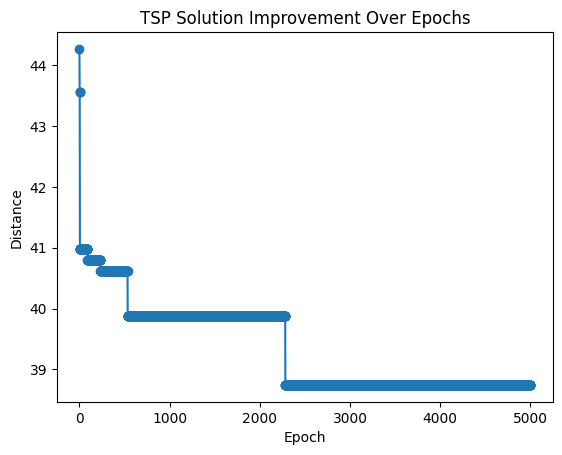

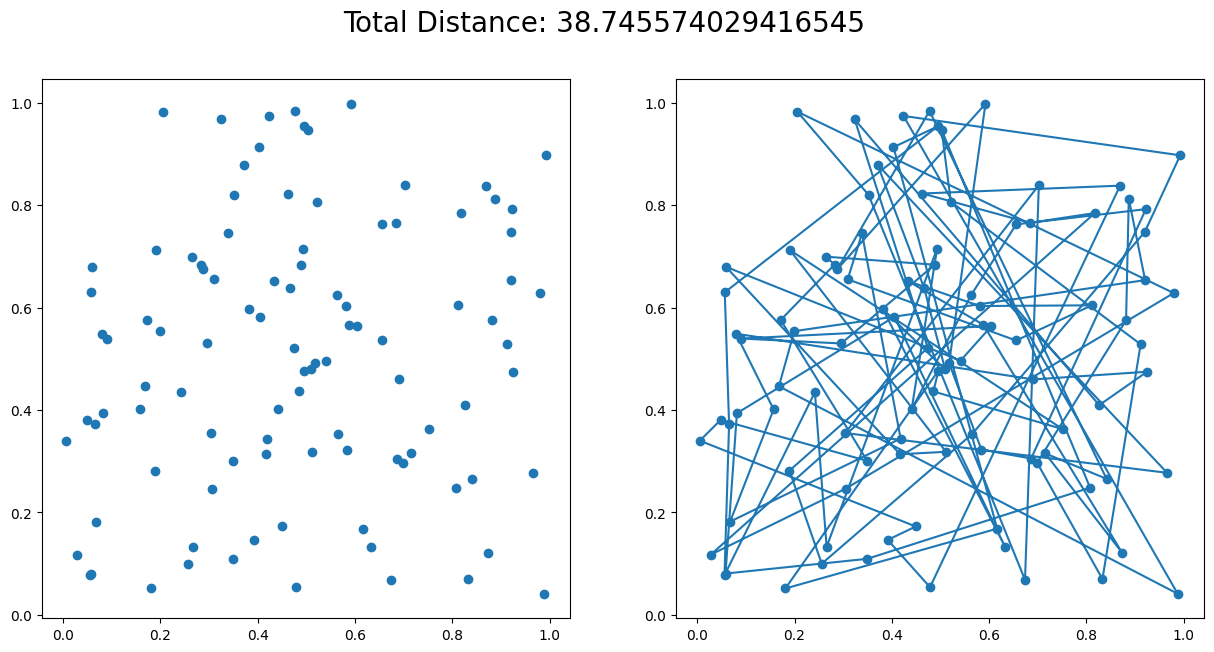

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import euclidean
import json
import os

plt.ion()  # turn interactive mode on

SAVE_FILE = 'best_tsp_solution.json'  # File to save/load the best solution


def read_cities(filepath):
    '''
    Load a TSP dataset.
    '''
    cities = np.loadtxt('/content/medium.csv', delimiter=',')
    return cities


def score_solution(cities, solution):
    '''
    Calculate the total distance traveled by the given solution.
    '''
    if len(solution) != len(cities):
        raise Exception(('Invalid solution: len(solution) is {}, ' +
                         'but it should be {}.').format(len(solution), len(cities)))

    if set(solution) != set(range(len(cities))):
        raise Exception('Invalid solution: The solution does not visit each city exactly once!')

    dist = 0.0
    for i in range(len(solution)):
        p_prev = cities[solution[i-1]]
        p_here = cities[solution[i]]
        dist += euclidean(p_prev, p_here)
    return dist


def load_best_solution():
    '''
    Load the best solution from a file, if available.
    '''
    if os.path.exists(SAVE_FILE):
        with open(SAVE_FILE, 'r') as file:
            data = json.load(file)
            best_solution = data['solution']
            best_dist = data['distance']
            print(f"Loaded previous best distance: {best_dist}")
            return np.array(best_solution), best_dist
    else:
        return None, float('inf')


def save_best_solution(solution, distance):
    '''
    Save the best solution to a file.
    '''
    data = {
        'solution': solution.tolist(),
        'distance': distance
    }
    with open(SAVE_FILE, 'w') as file:
        json.dump(data, file)
    print(f"Saved best distance: {distance}")


def create_figure():
    '''
    Creates a figure for `visualize_solution()`.
    '''
    fig, axes = plt.subplots(1, 2, figsize=(15, 7))
    return fig, axes


def visualize_solution(cities, solution, fig=None, axes=None, block=True):
    '''
    Visualize the solution in a 2D plot.
    '''
    dist = score_solution(cities, solution) if len(solution) == len(cities) else float('NaN')

    if fig is None or axes is None:
        fig, axes = create_figure()
    ax1, ax2 = axes
    fig.suptitle('Total Distance: {}'.format(dist), fontsize=20)

    ax1.clear()
    ax1.scatter(cities[:, 0], cities[:, 1])

    path = np.hstack((solution, solution[0]))  # salesperson returns home
    ax2.clear()
    ax2.plot(cities[path, 0], cities[path, 1])
    ax2.scatter(cities[:, 0], cities[:, 1])

    if block:
        while plt.fignum_exists(fig.number):
            plt.pause(0.001)
    else:
        plt.pause(0.001)


def tsp_solver_epochal(cities, epochs=100, iterations_per_epoch=1000, new_best_solution_func=None):
    '''
    TSP solver that improves solution across a number of epochs.
    '''
    # Load previous best solution if it exists
    best_solution, best_dist = load_best_solution()
    epoch_scores = []
    previous_best_dist = best_dist

    # If no previous solution exists, initialize randomly
    if best_solution is None:
        best_solution = np.arange(len(cities))
        np.random.shuffle(best_solution)
        best_dist = score_solution(cities, best_solution)

    for epoch in range(epochs):
        for _ in range(iterations_per_epoch):
            solution = np.arange(len(cities))
            np.random.shuffle(solution)
            dist = score_solution(cities, solution)
            if dist < best_dist:
                best_dist = dist
                best_solution = solution
                if new_best_solution_func:
                    new_best_solution_func(solution)

        # Only print if the best distance has improved
        if best_dist < previous_best_dist:
            print(f'Epoch {epoch + 1}/{epochs}, Best Distance: {best_dist}')
            previous_best_dist = best_dist  # Update the previous best distance

        epoch_scores.append(best_dist)

    # Save the best solution and distance after all epochs
    save_best_solution(best_solution, best_dist)

    # Plot the progress of the solution over epochs
    plt.figure()
    plt.plot(range(1, epochs + 1), epoch_scores, marker='o')
    plt.title('TSP Solution Improvement Over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Distance')
    plt.show()

    return best_solution


if __name__ == '__main__':
    cities = read_cities('/content/medium.csv')

    show_progress = False

    if not show_progress:
        solution = tsp_solver_epochal(cities, epochs=5000, iterations_per_epoch=100)
        visualize_solution(cities, solution)
    else:
        fig, axes = create_figure()

        def visualize_wrapper(solution, is_final=False):
            print('FINAL SOLUTION:' if is_final else 'Best so far:',
                  score_solution(cities, solution), solution)
            visualize_solution(cities, solution, fig, axes, block=is_final)

        solution = tsp_solver_epochal(cities, epochs=50, iterations_per_epoch=100, new_best_solution_func=visualize_wrapper)
        visualize_wrapper(solution, True)

## CLUSTERED TSP



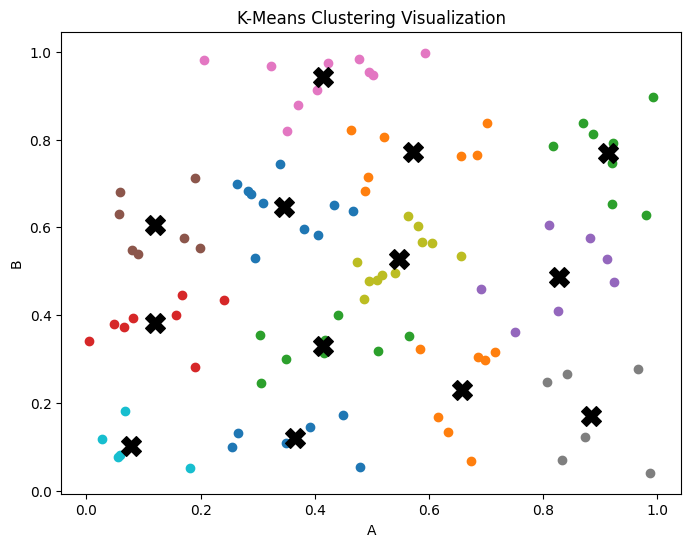

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Set the optimal number of clusters (you can adjust this based on the Elbow method)
optimal_k = 13

medium = pd.read_csv('medium.csv', names=['A', 'B'], header=None)

# Perform K-Means clustering
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
medium["Cluster"] = kmeans.fit_predict(medium[["A", "B"]])

# Plot the clusters
plt.figure(figsize=(8, 6))
for cluster in range(optimal_k):
    clustered_data = medium[medium["Cluster"] == cluster]
    plt.scatter(clustered_data["A"], clustered_data["B"], label=f"Cluster {cluster}")

# Plot cluster centers
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='black', marker='X', s=200, label="Centroids")

plt.xlabel("A")
plt.ylabel("B")
plt.title("K-Means Clustering Visualization")
#plt.legend()
plt.show()

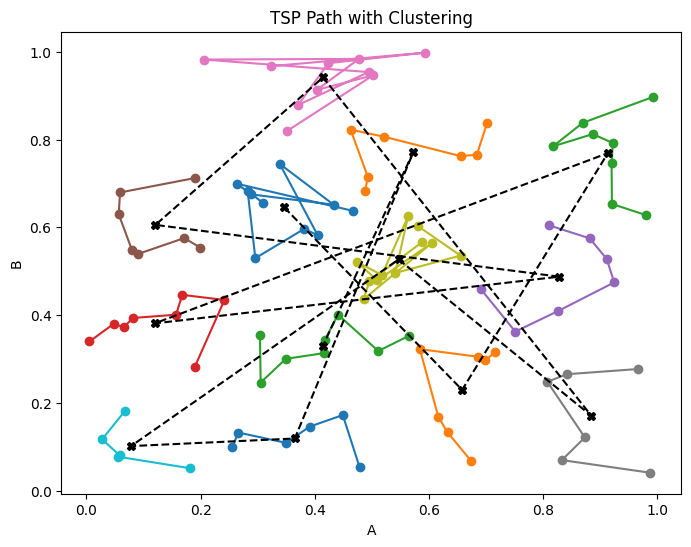

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import permutations
from sklearn.cluster import KMeans

# Function to solve TSP using brute force (for small clusters)
def solve_tsp_brute_force(points):
    if len(points) > 8:
        return points  # Skip brute force for large clusters

    min_path = None
    min_distance = float("inf")

    for perm in permutations(points):
        dist = sum(np.linalg.norm(np.array(perm[i]) - np.array(perm[i + 1])) for i in range(len(perm) - 1))
        if dist < min_distance:
            min_distance = dist
            min_path = perm

    return min_path

# Load dataset and perform clustering
medium = pd.read_csv('medium.csv', names=['A', 'B'], header=None)
optimal_k = 13
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
medium["Cluster"] = kmeans.fit_predict(medium[["A", "B"]])

# Solve TSP within each cluster
cluster_paths = {}
for cluster in range(optimal_k):
    cluster_points = medium[medium["Cluster"] == cluster][["A", "B"]].values
    cluster_paths[cluster] = solve_tsp_brute_force(cluster_points)

# Solve inter-cluster TSP using cluster centroids
cluster_centroids = kmeans.cluster_centers_
centroid_order = solve_tsp_brute_force(cluster_centroids)

# Plot the final TSP path
plt.figure(figsize=(8, 6))

# Plot intra-cluster paths
for cluster, path in cluster_paths.items():
    path = np.array(path)
    plt.plot(path[:, 0], path[:, 1], marker="o", linestyle="-", label=f"Cluster {cluster}")

# Plot inter-cluster path
centroid_order = np.array(centroid_order)
plt.plot(centroid_order[:, 0], centroid_order[:, 1], 'k--', marker="X", label="Inter-Cluster Path")

plt.xlabel("A")
plt.ylabel("B")
plt.title("TSP Path with Clustering")
#plt.legend()
plt.show()


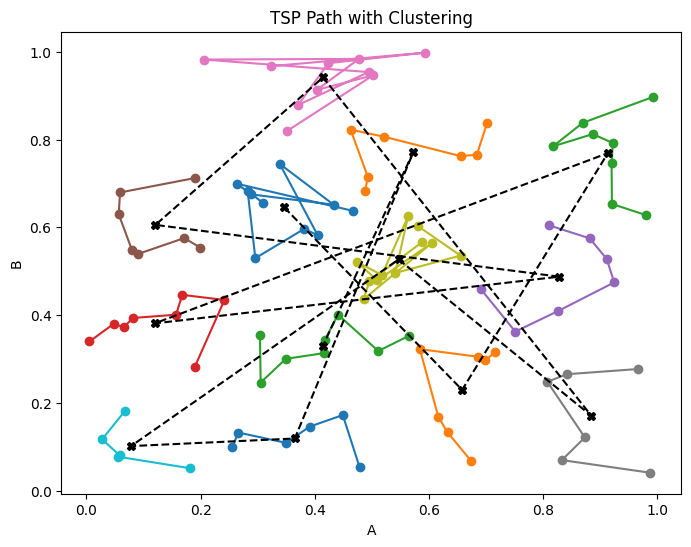

Total shortest distance: 15.57 units


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import permutations
from sklearn.cluster import KMeans

# Function to solve TSP using brute force (for small clusters)
def solve_tsp_brute_force(points):
    if len(points) > 8:
        return points  # Skip brute force for large clusters

    min_path = None
    min_distance = float("inf")

    for perm in permutations(points):
        dist = sum(np.linalg.norm(np.array(perm[i]) - np.array(perm[i + 1])) for i in range(len(perm) - 1))
        if dist < min_distance:
            min_distance = dist
            min_path = perm

    return min_path

# Load dataset and perform clustering
medium = pd.read_csv('medium.csv', names=['A', 'B'], header=None)
optimal_k = 13
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
medium["Cluster"] = kmeans.fit_predict(medium[["A", "B"]])

# Solve TSP within each cluster
cluster_paths = {}
for cluster in range(optimal_k):
    cluster_points = medium[medium["Cluster"] == cluster][["A", "B"]].values
    cluster_paths[cluster] = solve_tsp_brute_force(cluster_points)

# Solve inter-cluster TSP using cluster centroids
cluster_centroids = kmeans.cluster_centers_
centroid_order = solve_tsp_brute_force(cluster_centroids)

# Plot the final TSP path
plt.figure(figsize=(8, 6))

# Plot intra-cluster paths
for cluster, path in cluster_paths.items():
    path = np.array(path)
    plt.plot(path[:, 0], path[:, 1], marker="o", linestyle="-", label=f"Cluster {cluster}")

# Plot inter-cluster path
centroid_order = np.array(centroid_order)
plt.plot(centroid_order[:, 0], centroid_order[:, 1], 'k--', marker="X", label="Inter-Cluster Path")

plt.xlabel("A")
plt.ylabel("B")
plt.title("TSP Path with Clustering")
#plt.legend()
plt.show()

# 1. Calculate intra-cluster distances
intra_distances = []
for cluster, path in cluster_paths.items():
    if len(path) <= 1:  # Handle single-point clusters
        intra_distances.append(0)
        continue
    cluster_dist = sum(np.linalg.norm(np.array(path[i]) - np.array(path[i+1]))
                     for i in range(len(path)-1))
    intra_distances.append(cluster_dist)

# 2. Calculate inter-cluster distances using actual point transitions
inter_distance = 0
for i in range(len(centroid_order)-1):
    current_cluster = np.where(cluster_centroids == centroid_order[i])[0][0]
    next_cluster = np.where(cluster_centroids == centroid_order[i+1])[0][0]

    last_point = cluster_paths[current_cluster][-1]
    first_point = cluster_paths[next_cluster][0]
    inter_distance += np.linalg.norm(last_point - first_point)

# 3. Total distance calculation
total_distance = sum(intra_distances) + inter_distance
print(f"Total shortest distance: {total_distance:.2f} units")

In [ ]:
!pip install pygad

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 3.6 MB/s eta 0:00:00


In [ ]:
# import pygad
# import numpy as np

# def intra_cluster_ga(cluster_points, generations=100):
#     # Fitness function: Minimize path length
#     def fitness_func(ga_instance, solution, _):
#         path = cluster_points[solution]
#         dist = sum(np.linalg.norm(path[i] - path[i+1]) for i in range(len(path)-1))
#         return 1 / (dist + 1e-6)  # Inverse for maximization

#     # Initialize GA
#     ga = pygad.GA(
#         num_generations=generations,
#         num_parents_mating=2,
#         sol_per_pop=10,
#         num_genes=len(cluster_points),
#         gene_space=np.arange(len(cluster_points)),
#         fitness_func=fitness_func,
#         mutation_type="swap",
#         crossover_type="ordered"
#     )

#     ga.run()
#     best_solution = ga.best_solution()[0]
#     return cluster_points[best_solution]

In [ ]:
# def inter_cluster_ga(cluster_centroids, generations=50):
#     # Fitness function: Minimize inter-cluster transitions
#     def fitness_func(ga_instance, solution, _):
#         order = solution
#         dist = sum(np.linalg.norm(cluster_centroids[order[i]] -
#                                 cluster_centroids[order[i+1]])
#                  for i in range(len(order)-1))
#         return 1 / (dist + 1e-6)

#     ga = pygad.GA(
#         num_generations=generations,
#         num_parents_mating=2,
#         sol_per_pop=15,
#         num_genes=len(cluster_centroids),
#         gene_space=np.arange(len(cluster_centroids)),
#         fitness_func=fitness_func,
#         mutation_type="random",
#         crossover_type="single_point"
#     )

#     ga.run()
#     return ga.best_solution()[0]


Optimized Total Distance: 9.71 units


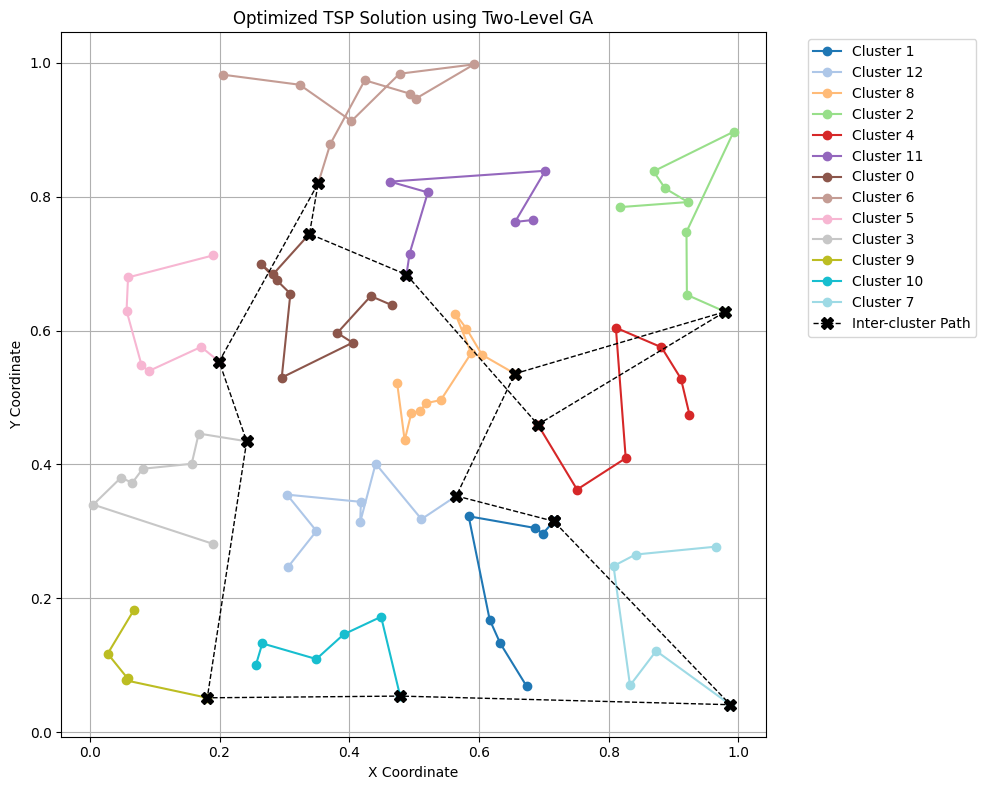

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pygad
from sklearn.cluster import KMeans

# Genetic Algorithm parameters
GA_CONFIG = {
    'intra': {
        'population_size': 50,
        'generations': 200,
        'mutation_type': "swap",
        'mutation_probability': 0.1
    },
    'inter': {
        'population_size': 30,
        'generations': 100,
        'crossover_type': "single_point",
        'mutation_type': "scramble",
        'mutation_probability': 0.2
    }
}

def tsp_distance(points):
    return sum(np.linalg.norm(points[i] - points[i+1]) for i in range(len(points)-1))

# Intra-cluster GA with fixed crossover and type handling
def intra_cluster_ga(cluster_points):
    if len(cluster_points) <= 1:
        return cluster_points

    # Custom Ordered Crossover (OX) for TSP permutations
    def tsp_crossover(parents, offspring_size, ga_instance):
        offspring = []
        idx = 0

        while len(offspring) < offspring_size[0]:
            parent1 = parents[idx % parents.shape[0], :].copy()
            parent2 = parents[(idx + 1) % parents.shape[0], :].copy()

            size = min(parent1.shape[0], parent2.shape[0])
            start, end = sorted(np.random.choice(range(size), 2, replace=False))

            child = -np.ones(size, dtype=int)
            child[start:end+1] = parent1[start:end+1]

            pointer = (end + 1) % size
            for gene in parent2:
                if gene not in child:
                    child[pointer] = gene
                    pointer = (pointer + 1) % size

            offspring.append(child)
            idx += 1

        return np.array(offspring)

    def fitness_func(ga, solution, _):
        # Convert float solutions to integers
        int_solution = solution.astype(int)
        ordered = cluster_points[int_solution]
        return 1 / (tsp_distance(ordered) + 1e-6)

    ga = pygad.GA(
        num_generations=GA_CONFIG['intra']['generations'],
        num_parents_mating=2,
        sol_per_pop=GA_CONFIG['intra']['population_size'],
        num_genes=len(cluster_points),
        gene_space=np.arange(len(cluster_points)),
        gene_type=int,  # Enforce integer genes
        fitness_func=fitness_func,
        crossover_type=tsp_crossover,
        mutation_type=GA_CONFIG['intra']['mutation_type'],
        mutation_probability=GA_CONFIG['intra']['mutation_probability'],
        allow_duplicate_genes=False,
        mutation_by_replacement=True,  # Keep within gene space
        suppress_warnings=True
    )

    ga.run()
    return cluster_points[ga.best_solution()[0].astype(int)]

# Inter-cluster GA with validation
def inter_cluster_ga(cluster_paths, centroids):
    n_clusters = len(cluster_paths)

    def fitness_func(ga, solution, _):
        int_solution = solution.astype(int)
        total_dist = 0
        for i in range(len(int_solution)-1):
            from_cluster = int_solution[i]
            to_cluster = int_solution[i+1]
            total_dist += np.linalg.norm(
                cluster_paths[from_cluster][-1] -
                cluster_paths[to_cluster][0]
            )
        return 1 / (total_dist + 1e-6)

    ga = pygad.GA(
        num_generations=GA_CONFIG['inter']['generations'],
        num_parents_mating=2,
        sol_per_pop=GA_CONFIG['inter']['population_size'],
        num_genes=n_clusters,
        gene_space=np.arange(n_clusters),
        gene_type=int,  # Enforce cluster indices as integers
        fitness_func=fitness_func,
        crossover_type=GA_CONFIG['inter']['crossover_type'],
        mutation_type=GA_CONFIG['inter']['mutation_type'],
        mutation_probability=GA_CONFIG['inter']['mutation_probability'],
        allow_duplicate_genes=False,
        mutation_by_replacement=True,
        suppress_warnings=True
    )

    ga.run()
    return ga.best_solution()[0].astype(int)

# Main execution flow
if __name__ == "__main__":
    # Load and cluster data
    medium = pd.read_csv('medium.csv', names=['A', 'B'], header=None)
    optimal_k = 13
    kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
    medium["Cluster"] = kmeans.fit_predict(medium[["A", "B"]])

    # Solve intra-cluster TSP with GA
    cluster_paths = {}
    for cluster in range(optimal_k):
        points = medium[medium["Cluster"] == cluster][["A", "B"]].values
        cluster_paths[cluster] = intra_cluster_ga(points)

    # Solve inter-cluster ordering with GA
    cluster_order = inter_cluster_ga(cluster_paths, kmeans.cluster_centers_)

    # Calculate total distance
    intra_total = sum(tsp_distance(path) for path in cluster_paths.values())
    inter_total = sum(np.linalg.norm(cluster_paths[cluster_order[i]][-1] -
                                    cluster_paths[cluster_order[i+1]][0])
                     for i in range(len(cluster_order)-1))

    print(f"Optimized Total Distance: {intra_total + inter_total:.2f} units")

    # Visualization
    plt.figure(figsize=(10, 8))
    colors = plt.cm.tab20(np.linspace(0, 1, optimal_k))

    # Plot intra-cluster paths
    for idx, cluster in enumerate(cluster_order):
        path = np.array(cluster_paths[cluster])
        plt.plot(path[:,0], path[:,1], marker='o', linestyle='-',
                color=colors[idx], label=f'Cluster {cluster}')

    # Plot inter-cluster connections
    inter_points = [cluster_paths[cluster][-1] for cluster in cluster_order]
    inter_points = np.array(inter_points + [inter_points[0]])
    plt.plot(inter_points[:,0], inter_points[:,1], 'k--', marker='X',
            linewidth=1, markersize=8, label='Inter-cluster Path')

    plt.title("Optimized TSP Solution using Two-Level GA")
    plt.xlabel("X Coordinate")
    plt.ylabel("Y Coordinate")
    plt.grid(True)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()


# LARGE DATASET

Epoch 1/1, Best Distance: 499.5430256287761
Saved best distance: 499.5430256287761


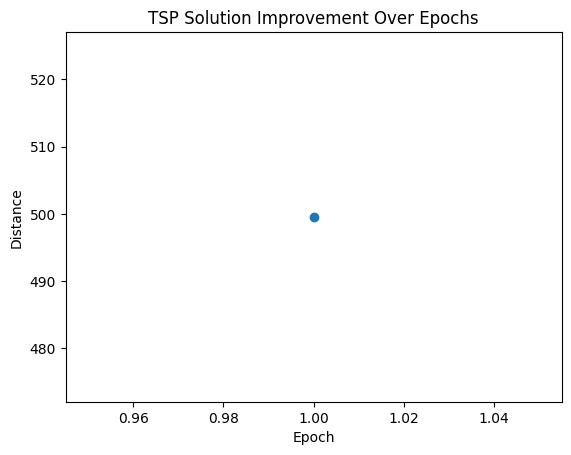

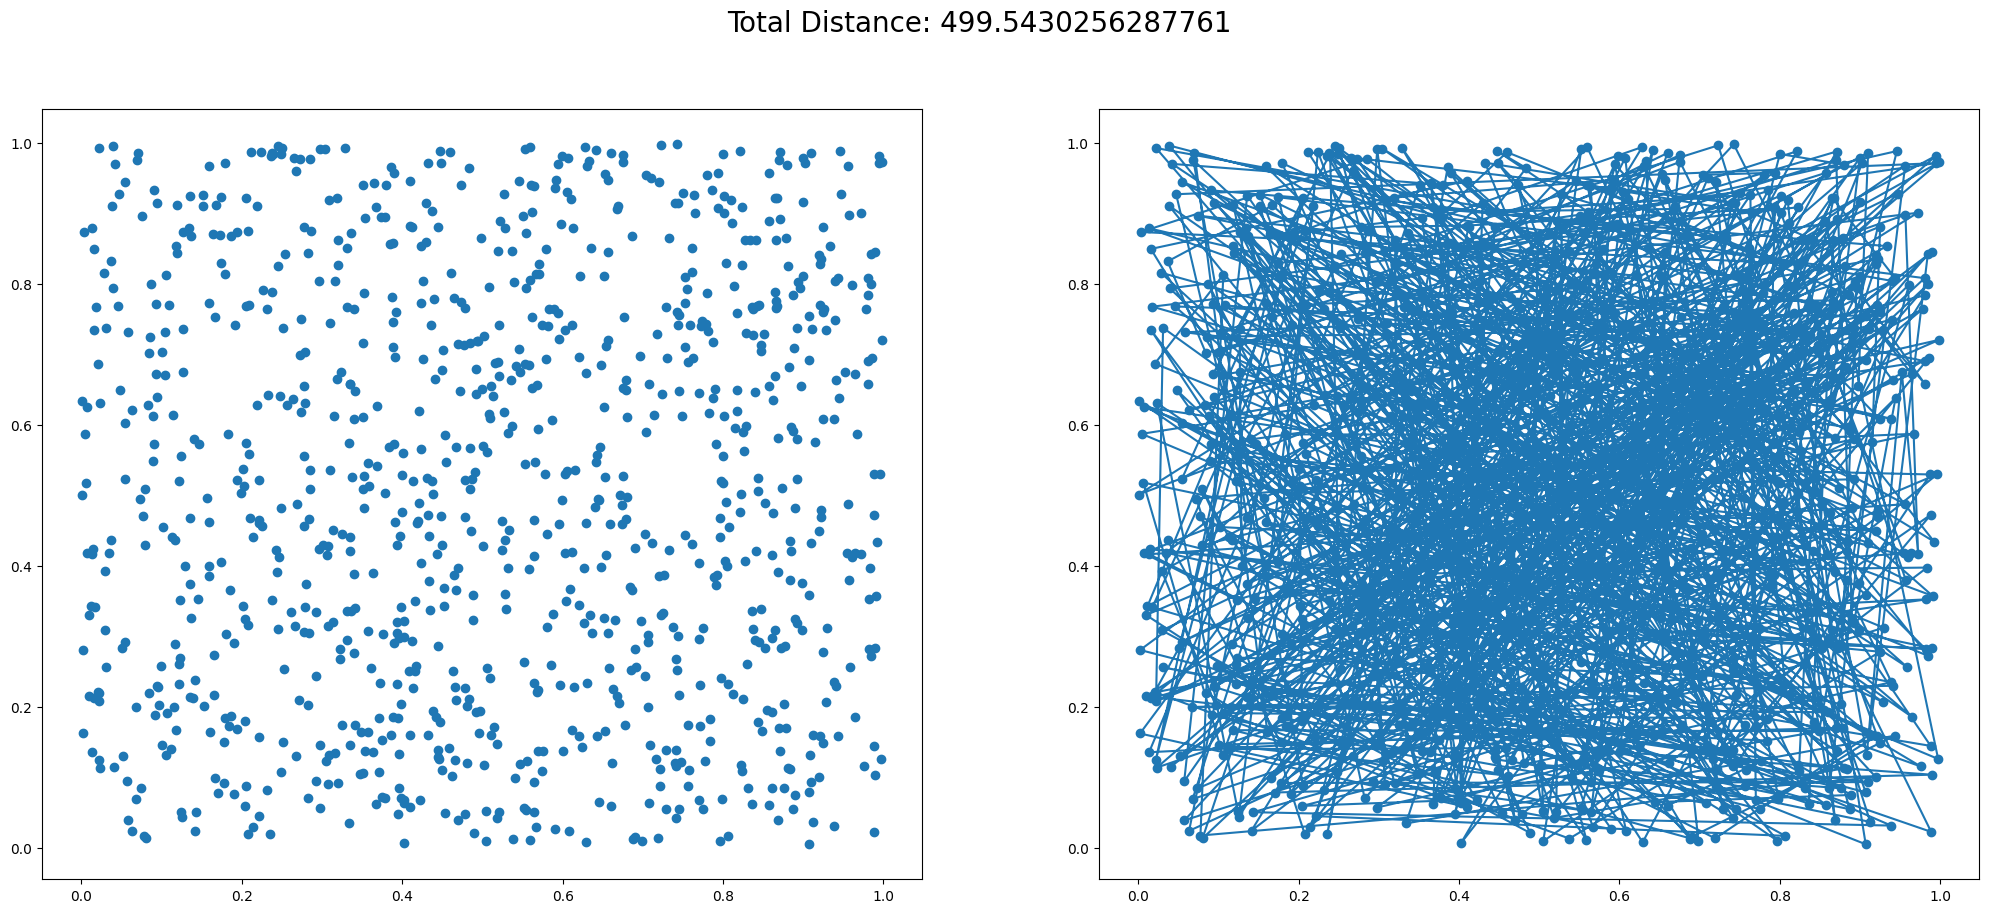

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import euclidean
import json
import os

plt.ion()  # turn interactive mode on

SAVE_FILE = 'best_tsp_solution_large.json'  # File to save/load the best solution


def read_cities(filepath):
    '''
    Load a TSP dataset.
    '''
    cities = np.loadtxt('/content/large.csv', delimiter=',')
    return cities


def score_solution(cities, solution):
    '''
    Calculate the total distance traveled by the given solution.
    '''
    if len(solution) != len(cities):
        raise Exception(('Invalid solution: len(solution) is {}, ' +
                         'but it should be {}.').format(len(solution), len(cities)))

    if set(solution) != set(range(len(cities))):
        raise Exception('Invalid solution: The solution does not visit each city exactly once!')

    dist = 0.0
    for i in range(len(solution)):
        p_prev = cities[solution[i-1]]
        p_here = cities[solution[i]]
        dist += euclidean(p_prev, p_here)
    return dist


def load_best_solution():
    '''
    Load the best solution from a file, if available.
    '''
    if os.path.exists(SAVE_FILE):
        with open(SAVE_FILE, 'r') as file:
            data = json.load(file)
            best_solution = data['solution']
            best_dist = data['distance']
            print(f"Loaded previous best distance: {best_dist}")
            return np.array(best_solution), best_dist
    else:
        return None, float('inf')


def save_best_solution(solution, distance):
    '''
    Save the best solution to a file.
    '''
    data = {
        'solution': solution.tolist(),
        'distance': distance
    }
    with open(SAVE_FILE, 'w') as file:
        json.dump(data, file)
    print(f"Saved best distance: {distance}")


def create_figure():
    '''
    Creates a figure for `visualize_solution()`.
    '''
    fig, axes = plt.subplots(1, 2, figsize=(25, 10))
    return fig, axes


def visualize_solution(cities, solution, fig=None, axes=None, block=True):
    '''
    Visualize the solution in a 2D plot.
    '''
    dist = score_solution(cities, solution) if len(solution) == len(cities) else float('NaN')

    if fig is None or axes is None:
        fig, axes = create_figure()
    ax1, ax2 = axes
    fig.suptitle('Total Distance: {}'.format(dist), fontsize=20)

    ax1.clear()
    ax1.scatter(cities[:, 0], cities[:, 1])

    path = np.hstack((solution, solution[0]))  # salesperson returns home
    ax2.clear()
    ax2.plot(cities[path, 0], cities[path, 1])
    ax2.scatter(cities[:, 0], cities[:, 1])

    if block:
        while plt.fignum_exists(fig.number):
            plt.pause(0.001)
    else:
        plt.pause(0.001)


def tsp_solver_epochal(cities, epochs=100, iterations_per_epoch=1000, new_best_solution_func=None):
    '''
    TSP solver that improves solution across a number of epochs.
    '''
    # Load previous best solution if it exists
    best_solution, best_dist = load_best_solution()
    epoch_scores = []
    previous_best_dist = best_dist

    # If no previous solution exists, initialize randomly
    if best_solution is None:
        best_solution = np.arange(len(cities))
        np.random.shuffle(best_solution)
        best_dist = score_solution(cities, best_solution)

    for epoch in range(epochs):
        for _ in range(iterations_per_epoch):
            solution = np.arange(len(cities))
            np.random.shuffle(solution)
            dist = score_solution(cities, solution)
            if dist < best_dist:
                best_dist = dist
                best_solution = solution
                if new_best_solution_func:
                    new_best_solution_func(solution)

        # Only print if the best distance has improved
        if best_dist < previous_best_dist:
            print(f'Epoch {epoch + 1}/{epochs}, Best Distance: {best_dist}')
            previous_best_dist = best_dist  # Update the previous best distance

        epoch_scores.append(best_dist)

    # Save the best solution and distance after all epochs
    save_best_solution(best_solution, best_dist)

    # Plot the progress of the solution over epochs
    plt.figure()
    plt.plot(range(1, epochs + 1), epoch_scores, marker='o')
    plt.title('TSP Solution Improvement Over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Distance')
    plt.show()

    return best_solution


if __name__ == '__main__':
    cities = read_cities('/content/large.csv')

    show_progress = False

    if not show_progress:
        solution = tsp_solver_epochal(cities, epochs=1, iterations_per_epoch=100)
        visualize_solution(cities, solution)
    else:
        fig, axes = create_figure()

        def visualize_wrapper(solution, is_final=False):
            print('FINAL SOLUTION:' if is_final else 'Best so far:',
                  score_solution(cities, solution), solution)
            visualize_solution(cities, solution, fig, axes, block=is_final)

        solution = tsp_solver_epochal(cities, epochs=50, iterations_per_epoch=100, new_best_solution_func=visualize_wrapper)
        visualize_wrapper(solution, True)

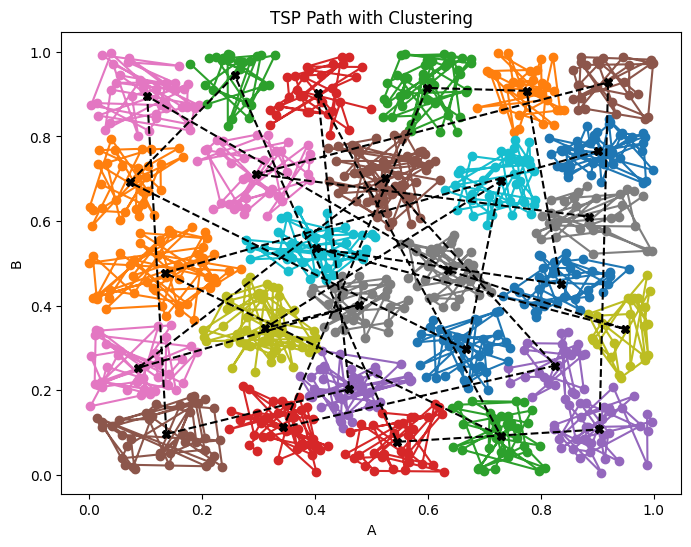

Total shortest distance: 108.31 units


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import permutations
from sklearn.cluster import KMeans

# Function to solve TSP using brute force (for small clusters)
def solve_tsp_brute_force(points):
    if len(points) > 8:
        return points  # Skip brute force for large clusters

    min_path = None
    min_distance = float("inf")

    for perm in permutations(points):
        dist = sum(np.linalg.norm(np.array(perm[i]) - np.array(perm[i + 1])) for i in range(len(perm) - 1))
        if dist < min_distance:
            min_distance = dist
            min_path = perm

    return min_path

# Load dataset and perform clustering
large = pd.read_csv('large.csv', names=['A', 'B'], header=None)
optimal_k = 28
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
large["Cluster"] = kmeans.fit_predict(large[["A", "B"]])

# Solve TSP within each cluster
cluster_paths = {}
for cluster in range(optimal_k):
    cluster_points = large[large["Cluster"] == cluster][["A", "B"]].values
    cluster_paths[cluster] = solve_tsp_brute_force(cluster_points)

# Solve inter-cluster TSP using cluster centroids
cluster_centroids = kmeans.cluster_centers_
centroid_order = solve_tsp_brute_force(cluster_centroids)

# Plot the final TSP path
plt.figure(figsize=(8, 6))

# Plot intra-cluster paths
for cluster, path in cluster_paths.items():
    path = np.array(path)
    plt.plot(path[:, 0], path[:, 1], marker="o", linestyle="-", label=f"Cluster {cluster}")

# Plot inter-cluster path
centroid_order = np.array(centroid_order)
plt.plot(centroid_order[:, 0], centroid_order[:, 1], 'k--', marker="X", label="Inter-Cluster Path")

plt.xlabel("A")
plt.ylabel("B")
plt.title("TSP Path with Clustering")
#plt.legend()
plt.show()

# 1. Calculate intra-cluster distances
intra_distances = []
for cluster, path in cluster_paths.items():
    if len(path) <= 1:  # Handle single-point clusters
        intra_distances.append(0)
        continue
    cluster_dist = sum(np.linalg.norm(np.array(path[i]) - np.array(path[i+1]))
                     for i in range(len(path)-1))
    intra_distances.append(cluster_dist)

# 2. Calculate inter-cluster distances using actual point transitions
inter_distance = 0
for i in range(len(centroid_order)-1):
    current_cluster = np.where(cluster_centroids == centroid_order[i])[0][0]
    next_cluster = np.where(cluster_centroids == centroid_order[i+1])[0][0]

    last_point = cluster_paths[current_cluster][-1]
    first_point = cluster_paths[next_cluster][0]
    inter_distance += np.linalg.norm(last_point - first_point)

# 3. Total distance calculation
total_distance = sum(intra_distances) + inter_distance
print(f"Total shortest distance: {total_distance:.2f} units")

Optimized Route Distance: 108.31 units


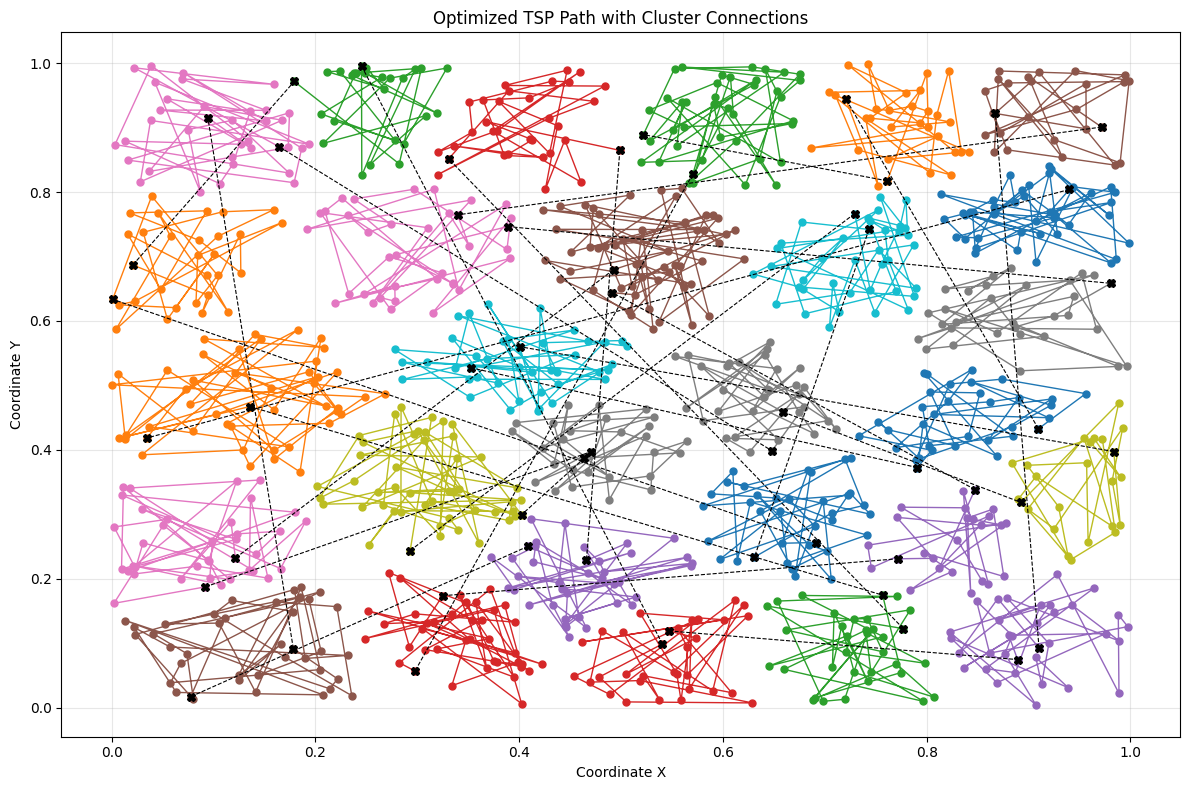

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import permutations
from sklearn.cluster import KMeans

# Function to solve TSP using brute force (for small clusters)
def solve_tsp_brute_force(points):
    if len(points) > 8:
        return points  # Skip brute force for large clusters
    if len(points) <= 1:
        return points  # Handle single-point clusters

    min_path = None
    min_distance = float("inf")

    for perm in permutations(points):
        dist = sum(np.linalg.norm(np.array(perm[i]) - np.array(perm[i + 1]))
                 for i in range(len(perm) - 1))
        if dist < min_distance:
            min_distance = dist
            min_path = perm

    return min_path

# Load dataset and perform clustering
large = pd.read_csv('large.csv', names=['A', 'B'], header=None)
optimal_k = 28
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
large["Cluster"] = kmeans.fit_predict(large[["A", "B"]])

# Solve TSP within each cluster
cluster_paths = {}
for cluster in range(optimal_k):
    cluster_points = large[large["Cluster"] == cluster][["A", "B"]].values
    cluster_paths[cluster] = solve_tsp_brute_force(cluster_points)

# Solve inter-cluster TSP using cluster centroids
cluster_centroids = kmeans.cluster_centers_
centroid_order = solve_tsp_brute_force(cluster_centroids)

# Create figure
plt.figure(figsize=(12, 8))

# 1. Plot intra-cluster paths
for cluster, path in cluster_paths.items():
    if len(path) == 0:
        continue
    path = np.array(path)
    plt.plot(path[:, 0], path[:, 1], marker="o", linestyle="-",
             markersize=5, linewidth=1, label=f"Cluster {cluster}")

# 2. Plot inter-cluster connections
inter_cluster_connections = []
for i in range(len(centroid_order) - 1):
    # Find actual cluster indices with tolerance for floating point comparisons
    current_mask = np.isclose(cluster_centroids, centroid_order[i], atol=1e-6).all(axis=1)
    next_mask = np.isclose(cluster_centroids, centroid_order[i+1], atol=1e-6).all(axis=1)

    current_cluster = np.where(current_mask)[0][0]
    next_cluster = np.where(next_mask)[0][0]

    # Get connection points
    start_point = cluster_paths[current_cluster][-1]
    end_point = cluster_paths[next_cluster][0]

    # Plot connection
    plt.plot([start_point[0], end_point[0]],
             [start_point[1], end_point[1]],
             'k--', linewidth=0.8, markersize=6, marker='X')

    inter_cluster_connections.append((start_point, end_point))

# 3. Final visualization formatting
plt.title("Optimized TSP Path with Cluster Connections")
plt.xlabel("Coordinate X")
plt.ylabel("Coordinate Y")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# 4. Calculate distances
intra_distance = sum(
    sum(np.linalg.norm(np.array(path[i]) - np.array(path[i+1]))
      for i in range(len(path)-1))
    for path in cluster_paths.values()
)

inter_distance = sum(
    np.linalg.norm(np.array(conn[0]) - np.array(conn[1]))
    for conn in inter_cluster_connections
)

total_distance = intra_distance + inter_distance
print(f"Optimized Route Distance: {total_distance:.2f} units")
plt.show()


Cluster Travel Order:
1. A (Cluster 0)
2. B (Cluster 1)
3. C (Cluster 2)
4. D (Cluster 3)
5. E (Cluster 4)
6. F (Cluster 5)
7. G (Cluster 6)
8. H (Cluster 7)
9. I (Cluster 8)
10. J (Cluster 9)
11. K (Cluster 10)
12. L (Cluster 11)
13. M (Cluster 12)
14. N (Cluster 13)
15. O (Cluster 14)
16. P (Cluster 15)
17. Q (Cluster 16)
18. R (Cluster 17)
19. S (Cluster 18)
20. T (Cluster 19)
21. U (Cluster 20)
22. V (Cluster 21)
23. W (Cluster 22)
24. X (Cluster 23)
25. Y (Cluster 24)
26. Z (Cluster 25)
27. AA (Cluster 26)
28. AB (Cluster 27)

Distance Breakdown:
Intra-cluster distance: 92.56
Inter-cluster distance: 15.75
Total distance: 108.31


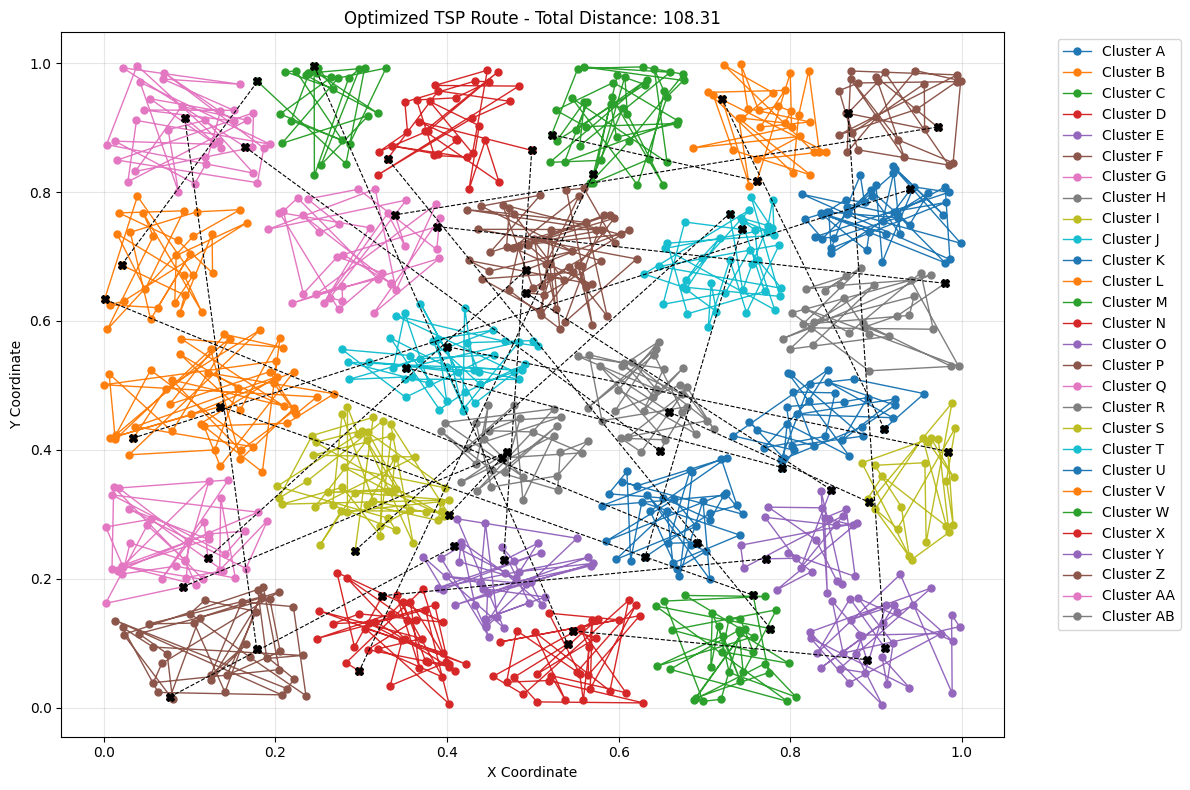

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import permutations
from sklearn.cluster import KMeans

# Cluster naming function (A, B, ..., Z, AA, AB, etc.)
def get_cluster_name(index):
    name = ""
    index += 1  # Start from 1 instead of 0
    while index > 0:
        index, remainder = divmod(index - 1, 26)
        name = chr(65 + remainder) + name
    return name

# TSP solver function
def solve_tsp_brute_force(points):
    if len(points) > 8 or len(points) <= 1:
        return points
    min_path = None
    min_distance = float("inf")
    for perm in permutations(points):
        dist = sum(np.linalg.norm(perm[i] - perm[i+1]) for i in range(len(perm)-1))
        if dist < min_distance:
            min_distance = dist
            min_path = perm
    return min_path

# Main execution
large = pd.read_csv('large.csv', names=['A', 'B'], header=None)
optimal_k = 28
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
large["Cluster"] = kmeans.fit_predict(large[["A", "B"]])

# Solve intra-cluster TSP and store paths
cluster_paths = {}
for cluster in range(optimal_k):
    points = large[large["Cluster"] == cluster][["A", "B"]].values
    cluster_paths[cluster] = solve_tsp_brute_force(points)

# Solve inter-cluster TSP using centroids
centroids = kmeans.cluster_centers_
centroid_order = solve_tsp_brute_force(centroids)

# Determine cluster travel order
travel_order = []
for centroid in centroid_order:
    # Find cluster index with tolerance for floating point precision
    mask = np.isclose(cluster_centroids, centroid, atol=1e-6).all(axis=1)
    cluster_idx = np.where(mask)[0][0]
    travel_order.append(cluster_idx)

# Visualization
plt.figure(figsize=(12, 8))
color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Plot intra-cluster paths
for idx, cluster in enumerate(travel_order):
    path = np.array(cluster_paths[cluster])
    if len(path) == 0:
        continue
    cluster_name = get_cluster_name(cluster)
    plt.plot(path[:, 0], path[:, 1], marker="o", linestyle="-",
             color=color_cycle[idx % len(color_cycle)],
             markersize=5, linewidth=1, label=f'Cluster {cluster_name}')

# Plot inter-cluster connections
inter_distances = []
for i in range(len(travel_order)-1):
    current_cluster = travel_order[i]
    next_cluster = travel_order[i+1]

    start_point = cluster_paths[current_cluster][-1]
    end_point = cluster_paths[next_cluster][0]

    distance = np.linalg.norm(start_point - end_point)
    inter_distances.append(distance)

    plt.plot([start_point[0], end_point[0]], [start_point[1], end_point[1]],
             'k--', linewidth=0.8, markersize=6, marker='X')

# Calculate total distance
intra_distance = sum(
    sum(np.linalg.norm(path[i]-path[i+1]) for i in range(len(path)-1))
    for path in cluster_paths.values()
)
inter_distance = sum(inter_distances)
total_distance = intra_distance + inter_distance

# Print results
print("Cluster Travel Order:")
for idx, cluster in enumerate(travel_order):
    print(f"{idx+1}. {get_cluster_name(cluster)} (Cluster {cluster})")

print(f"\nDistance Breakdown:")
print(f"Intra-cluster distance: {intra_distance:.2f}")
print(f"Inter-cluster distance: {inter_distance:.2f}")
print(f"Total distance: {total_distance:.2f}")

plt.title(f"Optimized TSP Route - Total Distance: {total_distance:.2f}")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Travelling Sequence:
cluster 0 --> cluster 1 --> cluster 2 --> cluster 3 --> cluster 4 --> cluster 5 --> cluster 6 --> cluster 7 --> cluster 8 --> cluster 9 --> cluster 10 --> cluster 11 --> cluster 12 --> cluster 13 --> cluster 14 --> cluster 15 --> cluster 16 --> cluster 17 --> cluster 18 --> cluster 19 --> cluster 20 --> cluster 21 --> cluster 22 --> cluster 23 --> cluster 24 --> cluster 25 --> cluster 26 --> cluster 27

Distance Breakdown:
Intra-cluster distance: 92.56
Inter-cluster distance: 15.75
Total optimized distance: 108.31


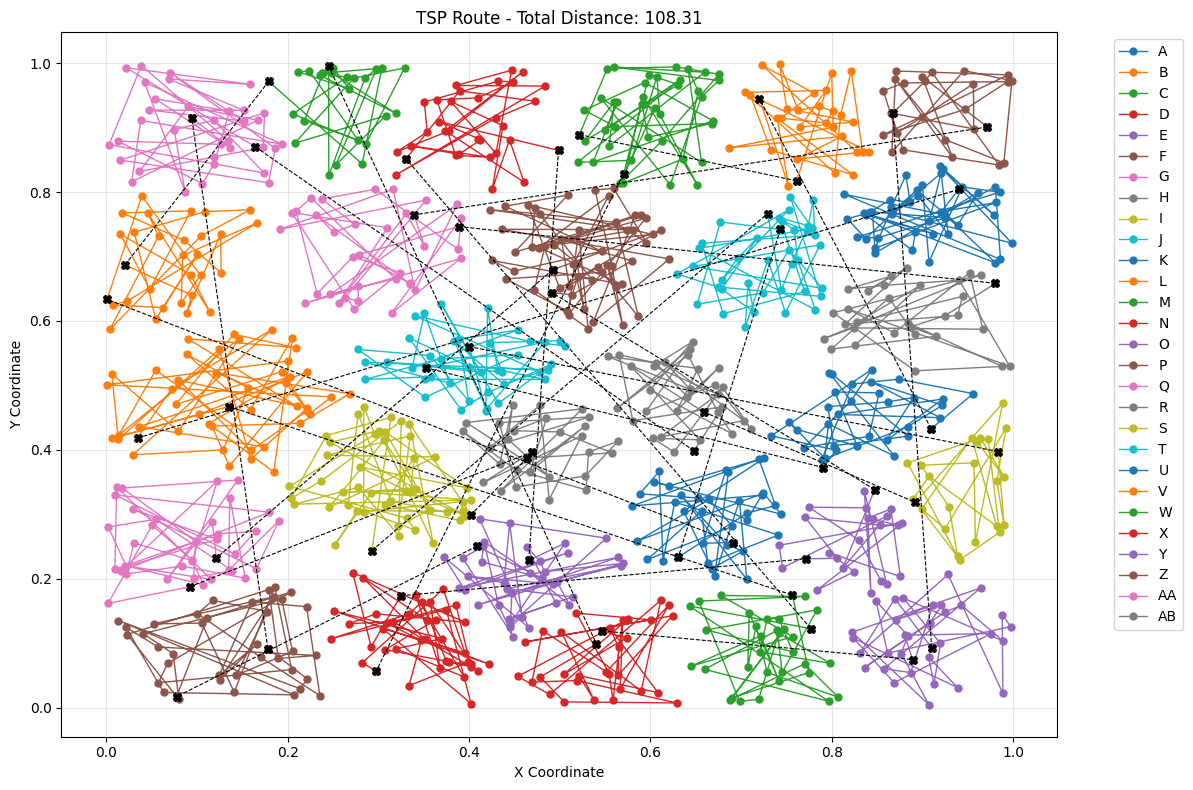

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import permutations
from sklearn.cluster import KMeans

def get_cluster_name(index):
    name = ""
    index += 1
    while index > 0:
        index, remainder = divmod(index - 1, 26)
        name = chr(65 + remainder) + name
    return name

def solve_tsp_brute_force(points):
    if len(points) > 8 or len(points) <= 1:
        return points
    min_path = None
    min_distance = float("inf")
    for perm in permutations(points):
        dist = sum(np.linalg.norm(perm[i] - perm[i+1]) for i in range(len(perm)-1))
        if dist < min_distance:
            min_distance = dist
            min_path = perm
    return min_path

# Main execution
large = pd.read_csv('large.csv', names=['A', 'B'], header=None)
optimal_k = 28
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
large["Cluster"] = kmeans.fit_predict(large[["A", "B"]])

# Solve intra-cluster TSP
cluster_paths = {}
for cluster in range(optimal_k):
    points = large[large["Cluster"] == cluster][["A", "B"]].values
    cluster_paths[cluster] = solve_tsp_brute_force(points)

# Solve inter-cluster TSP
centroids = kmeans.cluster_centers_
centroid_order = solve_tsp_brute_force(centroids)

# Determine travel order
travel_order = []
for centroid in centroid_order:
    mask = np.isclose(kmeans.cluster_centers_, centroid, atol=1e-6).all(axis=1)
    cluster_idx = np.where(mask)[0][0]
    travel_order.append(cluster_idx)

# Visualization
plt.figure(figsize=(12, 8))
color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Plot intra-cluster paths
for idx, cluster in enumerate(travel_order):
    path = np.array(cluster_paths[cluster])
    if len(path) == 0:
        continue
    plt.plot(path[:, 0], path[:, 1], marker="o", linestyle="-",
             color=color_cycle[idx % len(color_cycle)],
             markersize=5, linewidth=1, label=f'{get_cluster_name(cluster)}')

# Plot inter-cluster connections
inter_distances = []
for i in range(len(travel_order)-1):
    start = cluster_paths[travel_order[i]][-1]
    end = cluster_paths[travel_order[i+1]][0]
    distance = np.linalg.norm(start - end)
    inter_distances.append(distance)
    plt.plot([start[0], end[0]], [start[1], end[1]], 'k--', linewidth=0.8, markersize=6, marker='X')

# Calculate distances
intra_distance = sum(sum(np.linalg.norm(p[i]-p[i+1]) for i in range(len(p)-1)) for p in cluster_paths.values())
inter_distance = sum(inter_distances)
total_distance = intra_distance + inter_distance

# Print results in requested format
print("Travelling Sequence:")
print(" --> ".join([f"cluster {c}" for c in travel_order]))

print(f"\nDistance Breakdown:")
print(f"Intra-cluster distance: {intra_distance:.2f}")
print(f"Inter-cluster distance: {inter_distance:.2f}")
print(f"Total optimized distance: {total_distance:.2f}")

plt.title(f"TSP Route - Total Distance: {total_distance:.2f}")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


--- Intra-cluster Paths ---
Cluster 1: (0.89, 0.74) -> (0.89, 0.71) -> (0.84, 0.77) -> (0.91, 0.74) -> (0.84, 0.77) -> (0.98, 0.69) -> (0.93, 0.76) -> (0.81, 0.80) -> (0.99, 0.70) -> (0.98, 0.81) -> (0.91, 0.75) -> (0.92, 0.83) -> (0.87, 0.77) -> (0.90, 0.79) -> (0.93, 0.73) -> (0.92, 0.84) -> (0.98, 0.76) -> (0.92, 0.84) -> (1.00, 0.72) -> (0.87, 0.77) -> (0.89, 0.80) -> (0.94, 0.75) -> (0.96, 0.80) -> (0.85, 0.71) -> (0.84, 0.77) -> (0.82, 0.76) -> (0.84, 0.73) -> (0.90, 0.81) -> (0.91, 0.69) -> (0.94, 0.81) -> (0.99, 0.80) -> (0.83, 0.73) -> (0.85, 0.73) -> (0.93, 0.76) -> (0.84, 0.77) -> (0.86, 0.79) -> (0.89, 0.78) -> (0.88, 0.83) -> (0.87, 0.78) -> (0.85, 0.71) -> (0.98, 0.78) -> (0.92, 0.77) -> (0.94, 0.80)
Cluster 2: (0.03, 0.42) -> (0.07, 0.50) -> (0.18, 0.59) -> (0.03, 0.39) -> (0.13, 0.40) -> (0.16, 0.50) -> (0.09, 0.55) -> (0.16, 0.46) -> (0.21, 0.57) -> (0.18, 0.37) -> (0.11, 0.44) -> (0.20, 0.51) -> (0.04, 0.44) -> (0.17, 0.40) -> (0.05, 0.52) -> (0.01, 0.42) -> (0.15, 0.

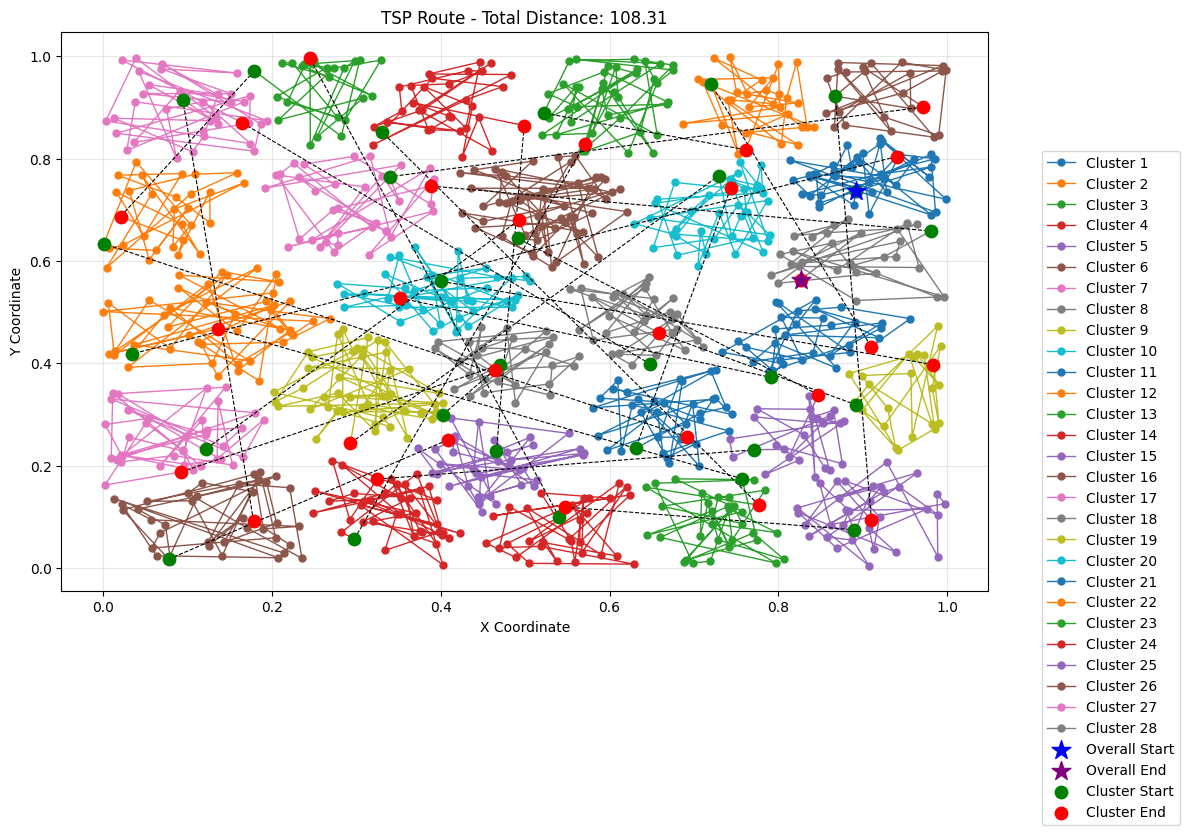

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import permutations
from sklearn.cluster import KMeans

def solve_tsp_brute_force(points):
    if len(points) > 8 or len(points) <= 1:
        return points
    min_path = None
    min_distance = float("inf")
    for perm in permutations(points):
        dist = sum(np.linalg.norm(perm[i] - perm[i+1]) for i in range(len(perm)-1))
        if dist < min_distance:
            min_distance = dist
            min_path = perm
    return min_path

# Main execution
large = pd.read_csv('large.csv', names=['A', 'B'], header=None)
optimal_k = 28
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
large["Cluster"] = kmeans.fit_predict(large[["A", "B"]])

# Solve intra-cluster TSP
cluster_paths = {}
intra_distances = []
for cluster in range(optimal_k):
    points = large[large["Cluster"] == cluster][["A", "B"]].values
    path = solve_tsp_brute_force(points)
    cluster_paths[cluster] = path

    # Calculate intra-cluster distance
    if len(path) > 1:
        dist = sum(np.linalg.norm(path[i] - path[i+1]) for i in range(len(path)-1))
        intra_distances.append(dist)
    else:
        intra_distances.append(0)

# Solve inter-cluster TSP
centroids = kmeans.cluster_centers_
centroid_order = solve_tsp_brute_force(centroids)

# Determine travel order
travel_order = []
for centroid in centroid_order:
    mask = np.isclose(kmeans.cluster_centers_, centroid, atol=1e-6).all(axis=1)
    cluster_idx = np.where(mask)[0][0]  # Fixed extraction of index
    travel_order.append(cluster_idx)

# Calculate inter-cluster distances
inter_distances = []
for i in range(len(travel_order)-1):
    start = cluster_paths[travel_order[i]][-1]  # Last point of current cluster
    end = cluster_paths[travel_order[i+1]][0]   # First point of next cluster
    distance = np.linalg.norm(np.array(start) - np.array(end))
    inter_distances.append(distance)

# Visualization
plt.figure(figsize=(12, 8))
color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Plot intra-cluster paths
for idx, cluster in enumerate(travel_order):
    path = np.array(cluster_paths[cluster])
    if len(path) == 0:
        continue
    plt.plot(path[:, 0], path[:, 1], marker="o", linestyle="-",
             color=color_cycle[idx % len(color_cycle)],
             markersize=5, linewidth=1, label=f'Cluster {cluster+1}')

# Add legend for the clusters only
handles, labels = plt.gca().get_legend_handles_labels()
unique_labels = []
unique_handles = []
for handle, label in zip(handles, labels):
    if label not in unique_labels:
        unique_labels.append(label)
        unique_handles.append(handle)
plt.legend(unique_handles, unique_labels, loc='upper left', bbox_to_anchor=(1.05, 1))

# Plot start and end points separately
for idx, cluster in enumerate(travel_order):
    path = np.array(cluster_paths[cluster])
    if len(path) == 0:
        continue
    # Start points in green
    plt.scatter(path[0, 0], path[0, 1], color="green", s=80, zorder=5)
    # End points in red
    plt.scatter(path[-1, 0], path[-1, 1], color="red", s=80, zorder=5)

# Plot inter-cluster connections
for i in range(len(travel_order)-1):
    start = cluster_paths[travel_order[i]][-1]
    end = cluster_paths[travel_order[i+1]][0]
    plt.plot([start[0], end[0]], [start[1], end[1]], 'k--', linewidth=0.8)

# Highlight overall start and end points
overall_start = cluster_paths[travel_order[0]][0]
overall_end = cluster_paths[travel_order[-1]][-1]
plt.scatter(overall_start[0], overall_start[1], color="blue", s=200, marker="*",
            zorder=10, label="Overall Start")
plt.scatter(overall_end[0], overall_end[1], color="purple", s=200, marker="*",
            zorder=10, label="Overall End")

# Add legend for start/end markers
plt.scatter([], [], color="green", s=80, label="Cluster Start")
plt.scatter([], [], color="red", s=80, label="Cluster End")
plt.legend(bbox_to_anchor=(1.05, 0.8))

# Calculate distances
intra_distance = sum(intra_distances)
inter_distance = sum(inter_distances)
total_distance = intra_distance + inter_distance

# Print results in the requested format
print("--- Intra-cluster Paths ---")
for idx, cluster in enumerate(range(optimal_k)):
    if cluster in cluster_paths and len(cluster_paths[cluster]) > 0:
        path = cluster_paths[cluster]
        path_str = " -> ".join([f"({p[0]:.2f}, {p[1]:.2f})" for p in path])
        print(f"Cluster {idx+1}: {path_str}")

print("\n--- Inter-cluster Path ---")
inter_path = " -> ".join([f"Cluster {c+1}" for c in travel_order])
print(inter_path)

print("\n--- Total Distance ---")
print(f"Intra-cluster Distance: {intra_distance:.2f}")
print(f"Inter-cluster Distance: {inter_distance:.2f}")
print(f"Overall Distance: {total_distance:.2f}")

print("\n--- Overall Route Start and End Points ---")
print(f"Start Point: ({overall_start[0]:.2f}, {overall_start[1]:.2f}) in Cluster {travel_order[0]+1}")
print(f"End Point: ({overall_end[0]:.2f}, {overall_end[1]:.2f}) in Cluster {travel_order[-1]+1}")

plt.title(f"TSP Route - Total Distance: {total_distance:.2f}")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Optimized Total Distance: 43.70 units


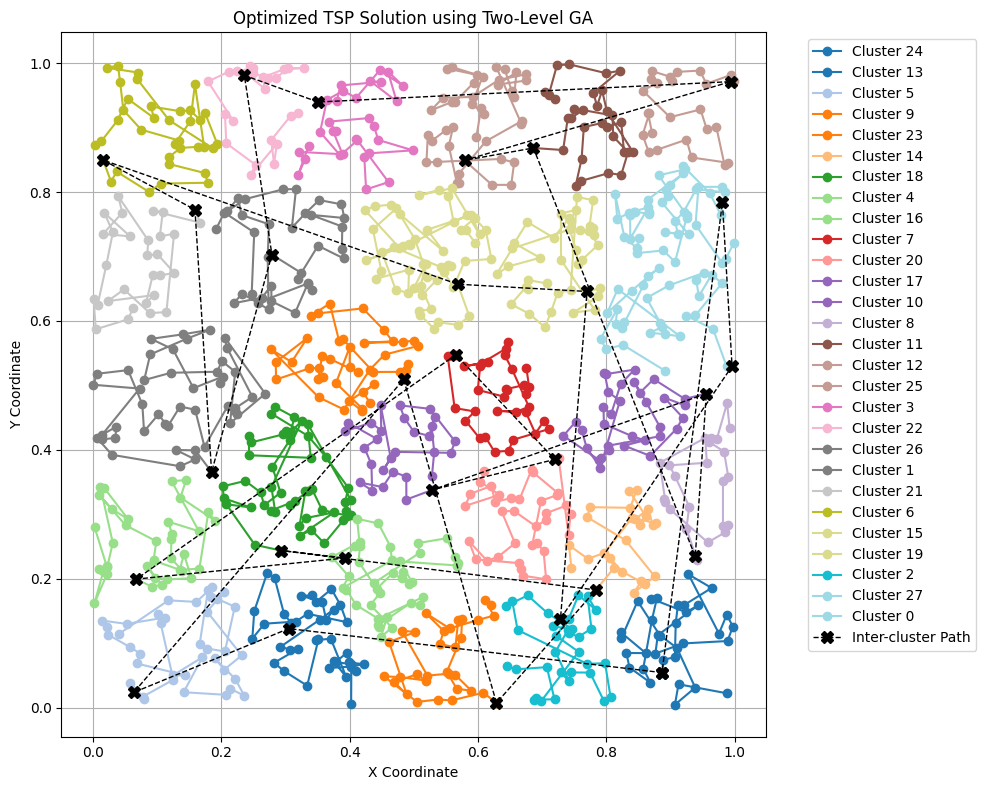

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pygad
from sklearn.cluster import KMeans

# Genetic Algorithm parameters
GA_CONFIG = {
    'intra': {
        'population_size': 50,
        'generations': 200,
        'mutation_type': "swap",
        'mutation_probability': 0.1
    },
    'inter': {
        'population_size': 30,
        'generations': 100,
        'crossover_type': "single_point",
        'mutation_type': "scramble",
        'mutation_probability': 0.2
    }
}

def tsp_distance(points):
    return sum(np.linalg.norm(points[i] - points[i+1]) for i in range(len(points)-1))

# Intra-cluster GA with fixed crossover and type handling
def intra_cluster_ga(cluster_points):
    if len(cluster_points) <= 1:
        return cluster_points

    # Custom Ordered Crossover (OX) for TSP permutations
    def tsp_crossover(parents, offspring_size, ga_instance):
        offspring = []
        idx = 0

        while len(offspring) < offspring_size[0]:
            parent1 = parents[idx % parents.shape[0], :].copy()
            parent2 = parents[(idx + 1) % parents.shape[0], :].copy()

            size = min(parent1.shape[0], parent2.shape[0])
            start, end = sorted(np.random.choice(range(size), 2, replace=False))

            child = -np.ones(size, dtype=int)
            child[start:end+1] = parent1[start:end+1]

            pointer = (end + 1) % size
            for gene in parent2:
                if gene not in child:
                    child[pointer] = gene
                    pointer = (pointer + 1) % size

            offspring.append(child)
            idx += 1

        return np.array(offspring)

    def fitness_func(ga, solution, _):
        # Convert float solutions to integers
        int_solution = solution.astype(int)
        ordered = cluster_points[int_solution]
        return 1 / (tsp_distance(ordered) + 1e-6)

    ga = pygad.GA(
        num_generations=GA_CONFIG['intra']['generations'],
        num_parents_mating=2,
        sol_per_pop=GA_CONFIG['intra']['population_size'],
        num_genes=len(cluster_points),
        gene_space=np.arange(len(cluster_points)),
        gene_type=int,  # Enforce integer genes
        fitness_func=fitness_func,
        crossover_type=tsp_crossover,
        mutation_type=GA_CONFIG['intra']['mutation_type'],
        mutation_probability=GA_CONFIG['intra']['mutation_probability'],
        allow_duplicate_genes=False,
        mutation_by_replacement=True,  # Keep within gene space
        suppress_warnings=True
    )

    ga.run()
    return cluster_points[ga.best_solution()[0].astype(int)]

# Inter-cluster GA with validation
def inter_cluster_ga(cluster_paths, centroids):
    n_clusters = len(cluster_paths)

    def fitness_func(ga, solution, _):
        int_solution = solution.astype(int)
        total_dist = 0
        for i in range(len(int_solution)-1):
            from_cluster = int_solution[i]
            to_cluster = int_solution[i+1]
            total_dist += np.linalg.norm(
                cluster_paths[from_cluster][-1] -
                cluster_paths[to_cluster][0]
            )
        return 1 / (total_dist + 1e-6)

    ga = pygad.GA(
        num_generations=GA_CONFIG['inter']['generations'],
        num_parents_mating=2,
        sol_per_pop=GA_CONFIG['inter']['population_size'],
        num_genes=n_clusters,
        gene_space=np.arange(n_clusters),
        gene_type=int,  # Enforce cluster indices as integers
        fitness_func=fitness_func,
        crossover_type=GA_CONFIG['inter']['crossover_type'],
        mutation_type=GA_CONFIG['inter']['mutation_type'],
        mutation_probability=GA_CONFIG['inter']['mutation_probability'],
        allow_duplicate_genes=False,
        mutation_by_replacement=True,
        suppress_warnings=True
    )

    ga.run()
    return ga.best_solution()[0].astype(int)

# Main execution flow
if __name__ == "__main__":
    # Load and cluster data
    large = pd.read_csv('large.csv', names=['A', 'B'], header=None)
    optimal_k = 28
    kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
    large["Cluster"] = kmeans.fit_predict(large[["A", "B"]])

    # Solve intra-cluster TSP with GA
    cluster_paths = {}
    for cluster in range(optimal_k):
        points = large[large["Cluster"] == cluster][["A", "B"]].values
        cluster_paths[cluster] = intra_cluster_ga(points)

    # Solve inter-cluster ordering with GA
    cluster_order = inter_cluster_ga(cluster_paths, kmeans.cluster_centers_)

    # Calculate total distance
    intra_total = sum(tsp_distance(path) for path in cluster_paths.values())
    inter_total = sum(np.linalg.norm(cluster_paths[cluster_order[i]][-1] -
                                    cluster_paths[cluster_order[i+1]][0])
                     for i in range(len(cluster_order)-1))

    print(f"Optimized Total Distance: {intra_total + inter_total:.2f} units")

    # Visualization
    plt.figure(figsize=(10, 8))
    colors = plt.cm.tab20(np.linspace(0, 1, optimal_k))

    # Plot intra-cluster paths
    for idx, cluster in enumerate(cluster_order):
        path = np.array(cluster_paths[cluster])
        plt.plot(path[:,0], path[:,1], marker='o', linestyle='-',
                color=colors[idx], label=f'Cluster {cluster}')

    # Plot inter-cluster connections
    inter_points = [cluster_paths[cluster][-1] for cluster in cluster_order]
    inter_points = np.array(inter_points + [inter_points[0]])
    plt.plot(inter_points[:,0], inter_points[:,1], 'k--', marker='X',
            linewidth=1, markersize=8, label='Inter-cluster Path')

    plt.title("Optimized TSP Solution using Two-Level GA")
    plt.xlabel("X Coordinate")
    plt.ylabel("Y Coordinate")
    plt.grid(True)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()


In [ ]:
!pip install pygad

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 6.2 MB/s eta 0:00:00


--- Intra-cluster Paths ---
Cluster 1: (1.00, 0.72) -> (0.99, 0.70) -> (0.98, 0.69) -> (0.91, 0.69) -> (0.89, 0.71) -> (0.87, 0.78) -> (0.86, 0.79) -> (0.89, 0.74) -> (0.91, 0.74) -> (0.91, 0.75) -> (0.85, 0.71) -> (0.85, 0.73) -> (0.84, 0.77) -> (0.84, 0.77) -> (0.81, 0.80) -> (0.84, 0.77) -> (0.90, 0.79) -> (0.89, 0.80) -> (0.90, 0.81) -> (0.92, 0.77) -> (0.94, 0.75) -> (0.93, 0.73) -> (0.98, 0.76) -> (0.98, 0.78) -> (0.96, 0.80) -> (0.99, 0.80) -> (0.98, 0.81) -> (0.94, 0.80) -> (0.94, 0.81) -> (0.93, 0.76) -> (0.85, 0.71) -> (0.84, 0.73) -> (0.83, 0.73) -> (0.82, 0.76) -> (0.84, 0.77) -> (0.87, 0.77) -> (0.87, 0.77) -> (0.89, 0.78) -> (0.88, 0.83) -> (0.92, 0.84) -> (0.92, 0.84) -> (0.92, 0.83) -> (0.93, 0.76)
Cluster 2: (0.20, 0.54) -> (0.19, 0.52) -> (0.18, 0.59) -> (0.21, 0.57) -> (0.21, 0.56) -> (0.20, 0.50) -> (0.20, 0.51) -> (0.22, 0.46) -> (0.27, 0.49) -> (0.25, 0.48) -> (0.22, 0.46) -> (0.21, 0.47) -> (0.22, 0.46) -> (0.14, 0.47) -> (0.16, 0.46) -> (0.13, 0.40) -> (0.17, 0.

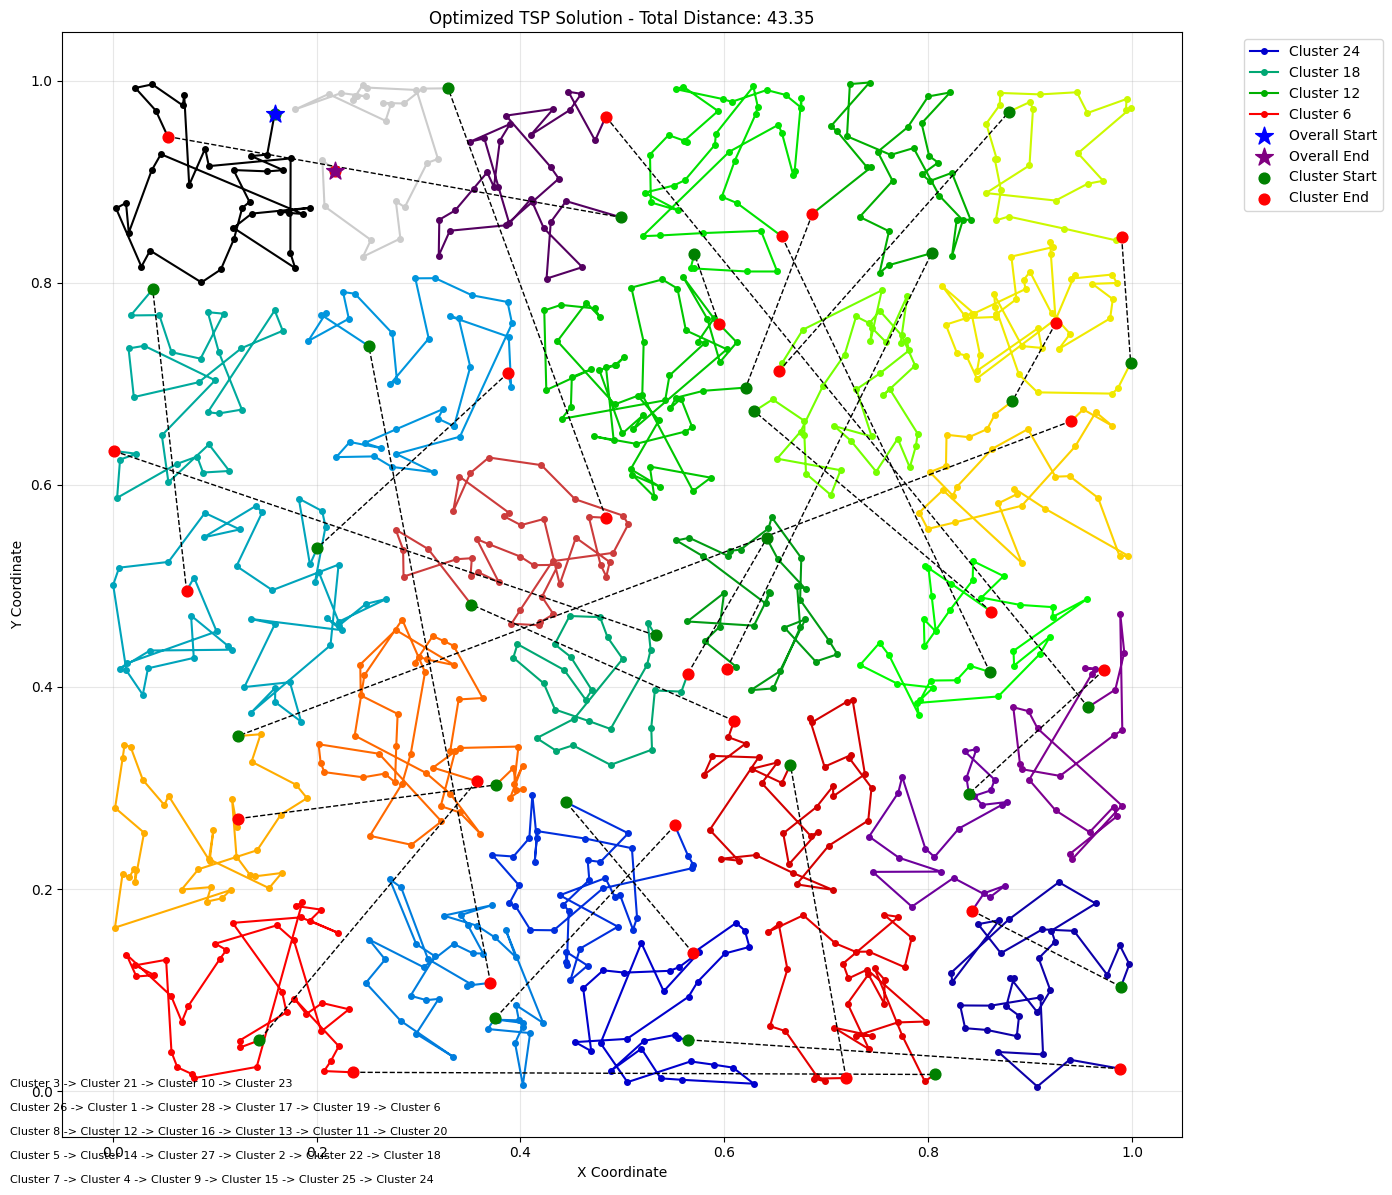

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pygad
from sklearn.cluster import KMeans

# Genetic Algorithm parameters
GA_CONFIG = {
    'intra': {
        'population_size': 50,
        'generations': 200,
        'mutation_type': "swap",
        'mutation_probability': 0.1
    },
    'inter': {
        'population_size': 30,
        'generations': 100,
        'crossover_type': "single_point",
        'mutation_type': "scramble",
        'mutation_probability': 0.2
    }
}

def tsp_distance(points):
    if len(points) <= 1:
        return 0
    return sum(np.linalg.norm(points[i] - points[i+1]) for i in range(len(points)-1))

# Intra-cluster GA with fixed crossover and type handling
def intra_cluster_ga(cluster_points):
    if len(cluster_points) <= 1:
        return cluster_points

    # Custom Ordered Crossover (OX) for TSP permutations
    def tsp_crossover(parents, offspring_size, ga_instance):
        offspring = []
        idx = 0

        while len(offspring) < offspring_size[0]:
            parent1 = parents[idx % parents.shape[0], :].copy()
            parent2 = parents[(idx + 1) % parents.shape[0], :].copy()

            size = min(parent1.shape[0], parent2.shape[0])
            start, end = sorted(np.random.choice(range(size), 2, replace=False))

            child = -np.ones(size, dtype=int)
            child[start:end+1] = parent1[start:end+1]

            pointer = (end + 1) % size
            for gene in parent2:
                if gene not in child:
                    child[pointer] = gene
                    pointer = (pointer + 1) % size

            offspring.append(child)
            idx += 1

        return np.array(offspring)

    def fitness_func(ga, solution, _):
        int_solution = solution.astype(int)
        ordered = cluster_points[int_solution]
        return 1 / (tsp_distance(ordered) + 1e-6)

    ga = pygad.GA(
        num_generations=GA_CONFIG['intra']['generations'],
        num_parents_mating=2,
        sol_per_pop=GA_CONFIG['intra']['population_size'],
        num_genes=len(cluster_points),
        gene_space=np.arange(len(cluster_points)),
        gene_type=int,
        fitness_func=fitness_func,
        crossover_type=tsp_crossover,
        mutation_type=GA_CONFIG['intra']['mutation_type'],
        mutation_probability=GA_CONFIG['intra']['mutation_probability'],
        allow_duplicate_genes=False,
        mutation_by_replacement=True,
        suppress_warnings=True
    )

    ga.run()
    return cluster_points[ga.best_solution()[0].astype(int)]

# Inter-cluster GA with validation
def inter_cluster_ga(cluster_paths, centroids):
    n_clusters = len(cluster_paths)

    def fitness_func(ga, solution, _):
        int_solution = solution.astype(int)
        total_dist = 0
        for i in range(len(int_solution)-1):
            from_cluster = int_solution[i]
            to_cluster = int_solution[i+1]
            total_dist += np.linalg.norm(
                cluster_paths[from_cluster][-1] -
                cluster_paths[to_cluster][0]
            )
        return 1 / (total_dist + 1e-6)

    ga = pygad.GA(
        num_generations=GA_CONFIG['inter']['generations'],
        num_parents_mating=2,
        sol_per_pop=GA_CONFIG['inter']['population_size'],
        num_genes=n_clusters,
        gene_space=np.arange(n_clusters),
        gene_type=int,
        fitness_func=fitness_func,
        crossover_type=GA_CONFIG['inter']['crossover_type'],
        mutation_type=GA_CONFIG['inter']['mutation_type'],
        mutation_probability=GA_CONFIG['inter']['mutation_probability'],
        allow_duplicate_genes=False,
        mutation_by_replacement=True,
        suppress_warnings=True
    )

    ga.run()
    return ga.best_solution()[0].astype(int)

# Main execution flow
if __name__ == "__main__":
    # Load and cluster data
    large = pd.read_csv('large.csv', names=['A', 'B'], header=None)
    optimal_k = 28  # Adjusted to 28 clusters as requested
    kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
    large["Cluster"] = kmeans.fit_predict(large[["A", "B"]])

    # Solve intra-cluster TSP with GA
    cluster_paths = {}
    for cluster in range(optimal_k):
        points = large[large["Cluster"] == cluster][["A", "B"]].values
        if len(points) > 0:
            cluster_paths[cluster] = intra_cluster_ga(points)

    # Solve inter-cluster ordering with GA
    cluster_order = inter_cluster_ga(cluster_paths, kmeans.cluster_centers_)

    # Calculate total distance
    intra_distances = {}
    for cluster, path in cluster_paths.items():
        intra_distances[cluster] = tsp_distance(path)

    intra_total = sum(intra_distances.values())

    # Calculate inter-cluster distances
    inter_distances = []
    for i in range(len(cluster_order)-1):
        from_cluster = cluster_order[i]
        to_cluster = cluster_order[i+1]
        if len(cluster_paths[from_cluster]) > 0 and len(cluster_paths[to_cluster]) > 0:
            distance = np.linalg.norm(
                cluster_paths[from_cluster][-1] -
                cluster_paths[to_cluster][0]
            )
            inter_distances.append(distance)

    inter_total = sum(inter_distances)
    overall_total = intra_total + inter_total

    # Print results in the desired format
    print("--- Intra-cluster Paths ---")
    for cluster in range(optimal_k):
        if cluster in cluster_paths and len(cluster_paths[cluster]) > 0:
            path = cluster_paths[cluster]
            path_str = " -> ".join([f"({p[0]:.2f}, {p[1]:.2f})" for p in path])
            print(f"Cluster {cluster+1}: {path_str}")

    print("\n--- Inter-cluster Path ---")
    inter_path = " -> ".join([f"Cluster {c+1}" for c in cluster_order])
    print(inter_path)

    print("\n--- Total Distance ---")
    print(f"Intra-cluster Distance: {intra_total:.2f}")
    print(f"Inter-cluster Distance: {inter_total:.2f}")
    print(f"Overall Distance: {overall_total:.2f}")

    # Visualization with enhanced clarity
    plt.figure(figsize=(14, 12))  # Larger figure for more clusters

    # Use a colormap that can handle more clusters
    colors = plt.cm.nipy_spectral(np.linspace(0, 1, optimal_k))

    # Plot intra-cluster paths with special markers for start/end
    for idx, cluster_num in enumerate(cluster_order):
        path = np.array(cluster_paths[cluster_num])
        if len(path) == 0:
            continue

        # Plot path
        plt.plot(path[:,0], path[:,1], marker='o', linestyle='-',
                color=colors[idx % len(colors)], markersize=4,
                label=f'Cluster {cluster_num+1}')

        # Mark start and end points distinctly
        plt.scatter(path[0,0], path[0,1], color='green', s=60, zorder=5)
        plt.scatter(path[-1,0], path[-1,1], color='red', s=60, zorder=5)

    # Plot inter-cluster connections
    for i in range(len(cluster_order)-1):
        from_cluster = cluster_order[i]
        to_cluster = cluster_order[i+1]
        start = cluster_paths[from_cluster][-1]  # Last point of current cluster
        end = cluster_paths[to_cluster][0]      # First point of next cluster

        plt.plot([start[0], end[0]], [start[1], end[1]], 'k--', linewidth=1.0)

    # Add overall start and end indicators
    overall_start = cluster_paths[cluster_order[0]][0]
    overall_end = cluster_paths[cluster_order[-1]][-1]
    plt.scatter(overall_start[0], overall_start[1], color='blue', s=180, marker='*',
                zorder=10, label='Overall Start')
    plt.scatter(overall_end[0], overall_end[1], color='purple', s=180, marker='*',
                zorder=10, label='Overall End')

    # Add a legend for the markers
    plt.scatter([], [], color='green', s=60, label='Cluster Start')
    plt.scatter([], [], color='red', s=60, label='Cluster End')

    plt.title(f"Optimized TSP Solution - Total Distance: {overall_total:.2f}")
    plt.xlabel("X Coordinate")
    plt.ylabel("Y Coordinate")
    plt.grid(True, alpha=0.3)

    # FIXED: Use a custom legend with only key information to avoid overcrowding
    handles, labels = plt.gca().get_legend_handles_labels()

    # Fixed version - safely process different label formats
    special_indices = []
    for i, label in enumerate(labels):
        if not label.startswith('Cluster'):
            # Keep all special markers (Start, End, etc.)
            special_indices.append(i)
        else:
            # For cluster labels, only keep a subset
            try:
                cluster_num = int(label.split()[1])
                if cluster_num % (optimal_k//5 + 1) == 0:
                    special_indices.append(i)
            except (ValueError, IndexError):
                # Handle any unexpected label formats
                special_indices.append(i)

    selected_handles = [handles[i] for i in special_indices]
    selected_labels = [labels[i] for i in special_indices]

    plt.legend(selected_handles, selected_labels, loc='upper left', bbox_to_anchor=(1.05, 1))

    # Add text annotation for the cluster sequence
    if len(inter_path) > 200:  # If the path string is too long
        segments = []
        current = ""
        for cluster in [f"Cluster {c+1}" for c in cluster_order]:
            if len(current + cluster) > 80:
                segments.append(current)
                current = cluster
            else:
                if current:
                    current += " -> " + cluster
                else:
                    current = cluster
        if current:
            segments.append(current)

        for i, segment in enumerate(segments):
            plt.figtext(0.01, 0.01 + i*0.02, segment, wrap=True, fontsize=8)
    else:
        plt.figtext(0.01, 0.01, "Cluster visit order: " + inter_path, wrap=True, fontsize=8)

    plt.tight_layout()
    plt.show()


--- Intra-cluster Paths ---
Cluster 1: (0.85, 0.73) -> (0.92, 0.77) -> (0.93, 0.76) -> (0.93, 0.76) -> (0.94, 0.75) -> (1.00, 0.72) -> (0.98, 0.69) -> (0.99, 0.70) -> (0.91, 0.69) -> (0.89, 0.71) -> (0.84, 0.73) -> (0.85, 0.71) -> (0.85, 0.71) -> (0.91, 0.75) -> (0.93, 0.73) -> (0.94, 0.80) -> (0.92, 0.83) -> (0.88, 0.83) -> (0.90, 0.81) -> (0.92, 0.84) -> (0.92, 0.84) -> (0.90, 0.79) -> (0.89, 0.80) -> (0.96, 0.80) -> (0.94, 0.81) -> (0.99, 0.80) -> (0.98, 0.81) -> (0.98, 0.78) -> (0.98, 0.76) -> (0.91, 0.74) -> (0.89, 0.74) -> (0.87, 0.78) -> (0.82, 0.76) -> (0.84, 0.77) -> (0.84, 0.77) -> (0.83, 0.73) -> (0.84, 0.77) -> (0.81, 0.80) -> (0.84, 0.77) -> (0.87, 0.77) -> (0.86, 0.79) -> (0.87, 0.77) -> (0.89, 0.78)
Cluster 2: (0.16, 0.40) -> (0.13, 0.40) -> (0.03, 0.42) -> (0.08, 0.43) -> (0.12, 0.52) -> (0.09, 0.57) -> (0.21, 0.56) -> (0.21, 0.57) -> (0.18, 0.59) -> (0.14, 0.58) -> (0.15, 0.57) -> (0.12, 0.56) -> (0.09, 0.55) -> (0.05, 0.52) -> (0.04, 0.44) -> (0.01, 0.42) -> (0.01, 0.

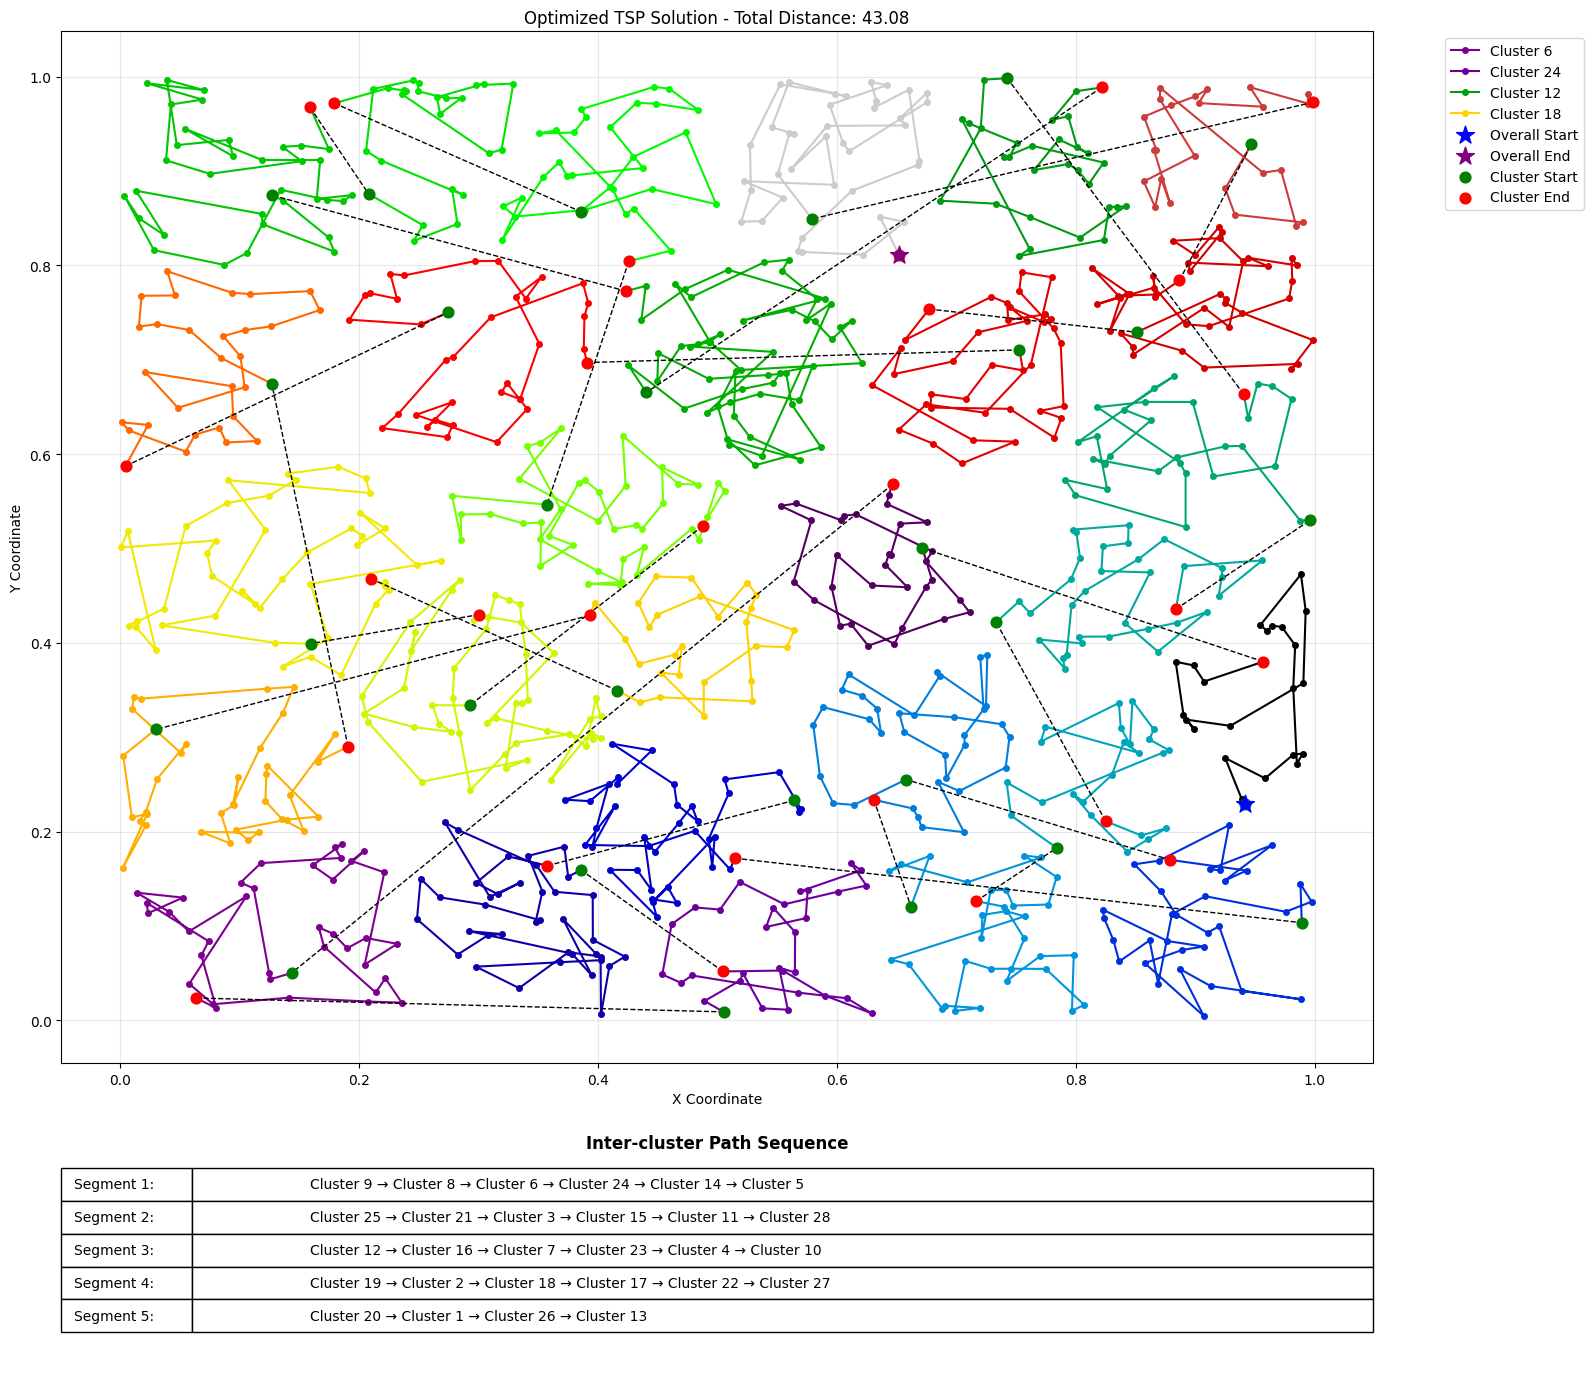

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pygad
from sklearn.cluster import KMeans
from matplotlib.gridspec import GridSpec

# Genetic Algorithm parameters
GA_CONFIG = {
    'intra': {
        'population_size': 50,
        'generations': 200,
        'mutation_type': "swap",
        'mutation_probability': 0.1
    },
    'inter': {
        'population_size': 30,
        'generations': 100,
        'crossover_type': "single_point",
        'mutation_type': "scramble",
        'mutation_probability': 0.2
    }
}

def tsp_distance(points):
    if len(points) <= 1:
        return 0
    return sum(np.linalg.norm(points[i] - points[i+1]) for i in range(len(points)-1))

# Intra-cluster GA with fixed crossover and type handling
def intra_cluster_ga(cluster_points):
    if len(cluster_points) <= 1:
        return cluster_points

    # Custom Ordered Crossover (OX) for TSP permutations
    def tsp_crossover(parents, offspring_size, ga_instance):
        offspring = []
        idx = 0

        while len(offspring) < offspring_size[0]:
            parent1 = parents[idx % parents.shape[0], :].copy()
            parent2 = parents[(idx + 1) % parents.shape[0], :].copy()

            size = min(parent1.shape[0], parent2.shape[0])
            start, end = sorted(np.random.choice(range(size), 2, replace=False))

            child = -np.ones(size, dtype=int)
            child[start:end+1] = parent1[start:end+1]

            pointer = (end + 1) % size
            for gene in parent2:
                if gene not in child:
                    child[pointer] = gene
                    pointer = (pointer + 1) % size

            offspring.append(child)
            idx += 1

        return np.array(offspring)

    def fitness_func(ga, solution, _):
        int_solution = solution.astype(int)
        ordered = cluster_points[int_solution]
        return 1 / (tsp_distance(ordered) + 1e-6)

    ga = pygad.GA(
        num_generations=GA_CONFIG['intra']['generations'],
        num_parents_mating=2,
        sol_per_pop=GA_CONFIG['intra']['population_size'],
        num_genes=len(cluster_points),
        gene_space=np.arange(len(cluster_points)),
        gene_type=int,
        fitness_func=fitness_func,
        crossover_type=tsp_crossover,
        mutation_type=GA_CONFIG['intra']['mutation_type'],
        mutation_probability=GA_CONFIG['intra']['mutation_probability'],
        allow_duplicate_genes=False,
        mutation_by_replacement=True,
        suppress_warnings=True
    )

    ga.run()
    return cluster_points[ga.best_solution()[0].astype(int)]

# Inter-cluster GA with validation
def inter_cluster_ga(cluster_paths, centroids):
    n_clusters = len(cluster_paths)

    def fitness_func(ga, solution, _):
        int_solution = solution.astype(int)
        total_dist = 0
        for i in range(len(int_solution)-1):
            from_cluster = int_solution[i]
            to_cluster = int_solution[i+1]
            total_dist += np.linalg.norm(
                cluster_paths[from_cluster][-1] -
                cluster_paths[to_cluster][0]
            )
        return 1 / (total_dist + 1e-6)

    ga = pygad.GA(
        num_generations=GA_CONFIG['inter']['generations'],
        num_parents_mating=2,
        sol_per_pop=GA_CONFIG['inter']['population_size'],
        num_genes=n_clusters,
        gene_space=np.arange(n_clusters),
        gene_type=int,
        fitness_func=fitness_func,
        crossover_type=GA_CONFIG['inter']['crossover_type'],
        mutation_type=GA_CONFIG['inter']['mutation_type'],
        mutation_probability=GA_CONFIG['inter']['mutation_probability'],
        allow_duplicate_genes=False,
        mutation_by_replacement=True,
        suppress_warnings=True
    )

    ga.run()
    return ga.best_solution()[0].astype(int)

# Main execution flow
if __name__ == "__main__":
    # Load and cluster data
    large = pd.read_csv('large.csv', names=['A', 'B'], header=None)
    optimal_k = 28  # Adjusted to 28 clusters as requested
    kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
    large["Cluster"] = kmeans.fit_predict(large[["A", "B"]])

    # Solve intra-cluster TSP with GA
    cluster_paths = {}
    for cluster in range(optimal_k):
        points = large[large["Cluster"] == cluster][["A", "B"]].values
        if len(points) > 0:
            cluster_paths[cluster] = intra_cluster_ga(points)

    # Solve inter-cluster ordering with GA
    cluster_order = inter_cluster_ga(cluster_paths, kmeans.cluster_centers_)

    # Calculate total distance
    intra_distances = {}
    for cluster, path in cluster_paths.items():
        intra_distances[cluster] = tsp_distance(path)

    intra_total = sum(intra_distances.values())

    # Calculate inter-cluster distances
    inter_distances = []
    for i in range(len(cluster_order)-1):
        from_cluster = cluster_order[i]
        to_cluster = cluster_order[i+1]
        if len(cluster_paths[from_cluster]) > 0 and len(cluster_paths[to_cluster]) > 0:
            distance = np.linalg.norm(
                cluster_paths[from_cluster][-1] -
                cluster_paths[to_cluster][0]
            )
            inter_distances.append(distance)

    inter_total = sum(inter_distances)
    overall_total = intra_total + inter_total

    # Print results in the desired format
    print("--- Intra-cluster Paths ---")
    for cluster in range(optimal_k):
        if cluster in cluster_paths and len(cluster_paths[cluster]) > 0:
            path = cluster_paths[cluster]
            path_str = " -> ".join([f"({p[0]:.2f}, {p[1]:.2f})" for p in path])
            print(f"Cluster {cluster+1}: {path_str}")

    print("\n--- Inter-cluster Path ---")
    inter_path = " -> ".join([f"Cluster {c+1}" for c in cluster_order])
    print(inter_path)

    print("\n--- Total Distance ---")
    print(f"Intra-cluster Distance: {intra_total:.2f}")
    print(f"Inter-cluster Distance: {inter_total:.2f}")
    print(f"Overall Distance: {overall_total:.2f}")

    # Create figure with proper layout
    fig = plt.figure(figsize=(16, 14))

    # Create a GridSpec layout to accommodate the path table
    gs = GridSpec(2, 1, height_ratios=[4, 1], figure=fig)

    # Main plot for TSP visualization
    ax1 = fig.add_subplot(gs[0])

    # Use a colormap that can handle more clusters
    colors = plt.cm.nipy_spectral(np.linspace(0, 1, optimal_k))

    # Plot intra-cluster paths with special markers for start/end
    for idx, cluster_num in enumerate(cluster_order):
        path = np.array(cluster_paths[cluster_num])
        if len(path) == 0:
            continue

        # Plot path
        ax1.plot(path[:,0], path[:,1], marker='o', linestyle='-',
                color=colors[idx % len(colors)], markersize=4,
                label=f'Cluster {cluster_num+1}')

        # Mark start and end points distinctly
        ax1.scatter(path[0,0], path[0,1], color='green', s=60, zorder=5)
        ax1.scatter(path[-1,0], path[-1,1], color='red', s=60, zorder=5)

    # Plot inter-cluster connections
    for i in range(len(cluster_order)-1):
        from_cluster = cluster_order[i]
        to_cluster = cluster_order[i+1]
        start = cluster_paths[from_cluster][-1]  # Last point of current cluster
        end = cluster_paths[to_cluster][0]      # First point of next cluster

        ax1.plot([start[0], end[0]], [start[1], end[1]], 'k--', linewidth=1.0)

    # Add overall start and end indicators
    overall_start = cluster_paths[cluster_order[0]][0]
    overall_end = cluster_paths[cluster_order[-1]][-1]
    ax1.scatter(overall_start[0], overall_start[1], color='blue', s=180, marker='*',
                zorder=10, label='Overall Start')
    ax1.scatter(overall_end[0], overall_end[1], color='purple', s=180, marker='*',
                zorder=10, label='Overall End')

    # Add a legend for the markers
    ax1.scatter([], [], color='green', s=60, label='Cluster Start')
    ax1.scatter([], [], color='red', s=60, label='Cluster End')

    ax1.set_title(f"Optimized TSP Solution - Total Distance: {overall_total:.2f}")
    ax1.set_xlabel("X Coordinate")
    ax1.set_ylabel("Y Coordinate")
    ax1.grid(True, alpha=0.3)

    # FIXED: Use a custom legend with only key information to avoid overcrowding
    handles, labels = ax1.get_legend_handles_labels()

    # Fixed version - safely process different label formats
    special_indices = []
    for i, label in enumerate(labels):
        if not label.startswith('Cluster'):
            # Keep all special markers (Start, End, etc.)
            special_indices.append(i)
        else:
            # For cluster labels, only keep a subset
            try:
                cluster_num = int(label.split()[1])
                if cluster_num % (optimal_k//5 + 1) == 0:
                    special_indices.append(i)
            except (ValueError, IndexError):
                # Handle any unexpected label formats
                special_indices.append(i)

    selected_handles = [handles[i] for i in special_indices]
    selected_labels = [labels[i] for i in special_indices]

    ax1.legend(selected_handles, selected_labels, loc='upper left', bbox_to_anchor=(1.05, 1))

    # Create a second subplot for the inter-cluster path
    ax2 = fig.add_subplot(gs[1])
    ax2.axis('off')  # Hide axes

    # NEW: Create a structured table for the inter-cluster path
    # Prepare the path data
    path_segments = []
    segment_labels = []

    # Split the path into readable segments, numbered for clarity
    clusters_per_row = 6  # Adjust based on figure width
    total_segments = (len(cluster_order) + clusters_per_row - 1) // clusters_per_row

    for i in range(total_segments):
        start_idx = i * clusters_per_row
        end_idx = min(start_idx + clusters_per_row, len(cluster_order))
        segment = " → ".join([f"Cluster {c+1}" for c in cluster_order[start_idx:end_idx]])
        path_segments.append(segment)
        segment_labels.append(f"Segment {i+1}:")

    # Create the table
    table_data = list(zip(segment_labels, path_segments))
    table = ax2.table(cellText=table_data,
                     colWidths=[0.1, 0.9],
                     loc='center',
                     cellLoc='left')

    # Format the table
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.5)

    # Add a title for the path table
    ax2.text(0.5, 0.95, "Inter-cluster Path Sequence",
             horizontalalignment='center',
             verticalalignment='top',
             transform=ax2.transAxes,
             fontsize=12,
             fontweight='bold')

    plt.tight_layout()
    plt.show()


# Constrained Path Large

In [ ]:
# ==========================================
# PART 1/8 — INSTALL + IMPORTS + CONFIG
# ==========================================

# Install pygad (Colab)
!pip install pygad

# Standard Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import pygad
import time
from collections import defaultdict
from itertools import combinations

%matplotlib inline

# ==========================================
# GLOBAL DEFAULTS (Modular for Experiments)
# ==========================================

DEFAULT_MIN_SAMPLES = 5          # DBSCAN density threshold
DEFAULT_EPS = "auto"             # Auto via k-distance knee
DEFAULT_D_MIN = 2                # Graph min degree (Suburban)
DEFAULT_D_MAX = 5                # Graph max degree (Suburban)
DEFAULT_START_NODE = 0           # Start delivery at node 0
DEFAULT_SHOW_PROGRESS = True     # Print updates during execution

# RNG for reproducibility (optional)
np.random.seed(42)

# ==========================================
# PART 2/8 — UTILITY HELPERS
# ==========================================

def euclidean_distance(p, q):
    return np.linalg.norm(p - q)

def pairwise_distances(points):
    """Compute full NxN distance matrix (used for small clusters)."""
    n = len(points)
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(i+1, n):
            d = np.linalg.norm(points[i] - points[j])
            D[i, j] = D[j, i] = d
    return D


# ---------------------------------------------------
# Knee detection for k-distance curve (Auto EPS)
# ---------------------------------------------------
def detect_knee(distances_sorted):
    """
    Lightweight knee detection.
    Finds point of maximum distance from the line connecting endpoints.
    """
    n = len(distances_sorted)
    x1, y1 = 0, distances_sorted[0]
    x2, y2 = n-1, distances_sorted[-1]

    # Line vector
    line_vec = np.array([x2 - x1, y2 - y1])
    line_vec = line_vec / np.linalg.norm(line_vec)

    # Compute distances from each point to the line
    distances_to_line = []
    for i in range(n):
        p = np.array([i, distances_sorted[i]])
        p1 = np.array([x1, y1])
        vec = p - p1
        dist = np.linalg.norm(vec - np.dot(vec, line_vec) * line_vec)
        distances_to_line.append(dist)

    knee_index = np.argmax(distances_to_line)
    return distances_sorted[knee_index]


# ---------------------------------------------------
# Plot utilities (used by visualization later)
# ---------------------------------------------------
def plot_points(points, labels=None, noise_mask=None, title=""):
    plt.figure(figsize=(8,6))
    if labels is None:
        plt.scatter(points[:,0], points[:,1], s=10)
    else:
        unique = np.unique(labels)
        for u in unique:
            mask = labels == u
            if u == -1:
                plt.scatter(points[mask,0], points[mask,1], s=20, marker='D', color='k', label='Noise')
            else:
                plt.scatter(points[mask,0], points[mask,1], s=20, label=f'Cluster {u}')
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend(bbox_to_anchor=(1.05,1), loc='upper left')
    plt.show()

# ==========================================
# PART 3/8 — DBSCAN + AUTO-EPS MODULE
# ==========================================

def compute_auto_eps(points, min_samples=DEFAULT_MIN_SAMPLES, show_plot=True):
    """
    Hybrid auto-eps:
    1. Compute k-distance curve
    2. Detect knee (auto)
    3. Plot for visual confirmation
    """
    k = max(1, min_samples - 1)
    nbrs = NearestNeighbors(n_neighbors=k+1).fit(points)
    distances, _ = nbrs.kneighbors(points)
    k_distances = np.sort(distances[:, k])

    # auto knee detection
    eps_est = detect_knee(k_distances)

    if show_plot:
        plt.figure(figsize=(7,5))
        plt.plot(k_distances)
        plt.axhline(eps_est, color='r', linestyle='--', label=f'Auto eps ≈ {eps_est:.4f}')
        plt.title(f'k-distance Knee Detection (k={k})')
        plt.xlabel('Point Index (sorted)')
        plt.ylabel(f'{k}-NN Distance')
        plt.grid(alpha=0.3)
        plt.legend()
        plt.show()

    return eps_est
from sklearn.cluster import KMeans

def perform_kmeans(points, k, show_plot=True, min_cluster_size=5):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(points)
    centroids = kmeans.cluster_centers_

    # Small cluster handling (optional)
    unique = np.unique(labels)
    for c in unique:
        idx = np.where(labels == c)[0]
        if len(idx) < min_cluster_size:
            # reassign to nearest centroid
            for i in idx:
                d = np.linalg.norm(centroids - points[i], axis=1)
                new = np.argmin(d)
                labels[i] = new

    unique = np.unique(labels)
    num_clusters = len(unique)

    noise_nodes = []  # none for K-Means

    if show_plot:
        plt.figure(figsize=(8,6))
        cmap = plt.cm.get_cmap('tab20', num_clusters)
        for c in unique:
            pts = points[labels==c]
            plt.scatter(pts[:,0], pts[:,1], s=18, color=cmap(c), label=f"C{c}")
        plt.title(f"KMeans Clusters (K={num_clusters})")
        plt.grid(alpha=0.3)
        plt.legend(bbox_to_anchor=(1.05,1), loc='upper left')
        plt.show()

    return labels, num_clusters, noise_nodes, centroids

def perform_dbscan(points, min_samples=DEFAULT_MIN_SAMPLES, eps=DEFAULT_EPS, show_plot=True):
    """
    Wrapper for DBSCAN with hybrid auto-eps mode.
    Returns:
        cluster_labels: array of size N
        num_clusters: number of dense clusters (excluding noise)
        noise_indices: list of node IDs considered noise
    """
    # determine eps automatically if requested
    if eps == "auto":
        eps = compute_auto_eps(points, min_samples, show_plot=show_plot)

    db = DBSCAN(eps=eps, min_samples=min_samples).fit(points)
    labels = db.labels_

    # number of clusters excluding noise = -1
    dense_clusters = [c for c in np.unique(labels) if c != -1]
    num_clusters = len(dense_clusters)

    # noise handling (Option C)
    noise_indices = np.where(labels == -1)[0].tolist()

    if show_plot:
        plot_points(points, labels=labels, title=f"DBSCAN Clusters (dense={num_clusters}, noise={len(noise_indices)})")

    return labels, num_clusters, noise_indices, eps


# ==========================================
# PART 4/8 — DEGREE-CONSTRAINED GRAPH
# ==========================================

def build_suburban_graph(points, d_min=DEFAULT_D_MIN, d_max=DEFAULT_D_MAX, show_progress=True):
    """
    Builds a sparse undirected degree-constrained graph:
    - Each node connects to >= d_min neighbors
    - Max degree capped at d_max
    - Ensures strong connectivity
    Returns:
        adj: adjacency list {node: [(neighbor, weight), ...]}
        edges: list of (u, v, weight)
    """
    N = len(points)
    adj = defaultdict(list)

    # Precompute all distances (local KNN only)
    nbrs = NearestNeighbors(n_neighbors=d_max+1).fit(points)
    distances, indices = nbrs.kneighbors(points)

    # Step 1: enforce minimum degree using nearest neighbors
    for u in range(N):
        for k in range(1, d_min+1):
            v = indices[u, k]
            w = np.linalg.norm(points[u] - points[v])
            adj[u].append((v, w))
            adj[v].append((u, w))  # undirected

    # Step 2: randomly add edges up to max degree
    for u in range(N):
        current_deg = len(adj[u])
        for k in range(d_min+1, d_max+1):
            if current_deg >= d_max:
                break
            v = indices[u, k]
            w = np.linalg.norm(points[u] - points[v])
            if v not in [x for x,_ in adj[u]]:
                adj[u].append((v,w))
                adj[v].append((u,w))
                current_deg += 1

    # Step 3: ensure connectivity via BFS
    visited = set()
    stack = [0]
    while stack:
        u = stack.pop()
        if u not in visited:
            visited.add(u)
            stack += [v for v,_ in adj[u]]

    # Connect disconnected components
    if len(visited) != N:
        if show_progress: print("Graph disconnected — bridging components...")
        unvisited = set(range(N)) - visited
        for u in unvisited:
            # connect to nearest visited node
            dists = np.linalg.norm(points[list(visited)] - points[u], axis=1)
            idx = np.argmin(dists)
            v = list(visited)[idx]
            w = np.linalg.norm(points[u] - points[v])
            adj[u].append((v,w))
            adj[v].append((u,w))
            visited.add(u)

    # Collect edge list
    edges = []
    seen = set()
    for u in adj:
        for v,w in adj[u]:
            if (v,u) not in seen:
                edges.append((u,v,w))
                seen.add((u,v))

    if show_progress:
        print(f"Graph built: nodes={N}, edges={len(edges)}, avg_deg ≈ {2*len(edges)/N:.2f}")

    return adj, edges


# ==========================================
# PART 5/8 — BOUNDARY MINIMAL CLUSTER GRAPH
# ==========================================

def build_boundary_cluster_graph(points, labels, adj, num_clusters, noise_indices, show_progress=True):
    """
    Constructs the cluster-level boundary graph using minimal inter-cluster edges.
    Returns:
        cluster_edges: {(ci,cj): (cost, u, v)}
        cluster_nodes: {ci: [node_ids]}
    """

    # Collect nodes for each dense cluster
    cluster_nodes = {c: [] for c in range(num_clusters)}
    for node, label in enumerate(labels):
        if label != -1:
            cluster_nodes[label].append(node)

    # Build inter-cluster boundary edges
    cluster_edges = {}  # key: (ci,cj), val: (cost, u, v)

    for ci in range(num_clusters):
        for cj in range(ci+1, num_clusters):
            min_cost = float('inf')
            gateway_u, gateway_v = None, None

            # examine all edges between Ci and Cj using the graph
            for u in cluster_nodes[ci]:
                for v, w in adj[u]:
                    if labels[v] == cj:
                        if w < min_cost:
                            min_cost = w
                            gateway_u = u
                            gateway_v = v

            if min_cost < float('inf'):
                cluster_edges[(ci, cj)] = (min_cost, gateway_u, gateway_v)
                cluster_edges[(cj, ci)] = (min_cost, gateway_v, gateway_u)

    if show_progress:
        print(f"Boundary cluster graph built: clusters={num_clusters}, inter-links={len(cluster_edges)//2}")

    return cluster_edges, cluster_nodes


# ==========================================
# PART 6/8 — GENETIC ALGORITHMS (pygad)
# ==========================================

# ------------------------
# Distance Helpers
# ------------------------
def path_distance(path, points):
    total = 0.0
    for i in range(len(path)-1):
        total += euclidean_distance(points[path[i]], points[path[i+1]])
    return total


# ==========================================
# 6A — Intra-Cluster GA
# ==========================================
def solve_intra_cluster(points, cluster_nodes, start_node=None):
    """
    Solve Hamiltonian path inside a cluster using GA.
    Handles degenerate cluster sizes + corrects gene_space for start pinning.
    """

    n = len(cluster_nodes)

    # ----- Degenerate Cases -----
    if n <= 1:
        return cluster_nodes

    if n == 2:
        if start_node is not None and start_node in cluster_nodes:
            other = [x for x in cluster_nodes if x != start_node]
            return [start_node] + other
        return cluster_nodes

    if n == 3:
        from itertools import permutations
        best = None
        bestd = float('inf')
        for perm in permutations(cluster_nodes):
            if start_node is not None and perm[0] != start_node:
                continue
            d = path_distance(perm, points)
            if d < bestd:
                best = perm
                bestd = d
        return list(best)

    # ----- Normal Case (n >= 4, use GA) -----
    nodes = cluster_nodes.copy()

    if start_node is not None:
        nodes.remove(start_node)
        ordering = [start_node] + nodes
        permutable = ordering[1:]
        num_genes = len(permutable)
        gene_space = list(range(num_genes))
    else:
        ordering = nodes.copy()
        permutable = ordering
        num_genes = len(permutable)
        gene_space = list(range(num_genes))

    def fitness_func(ga, solution, idx):
        if start_node is not None:
            permuted = [permutable[i] for i in solution.astype(int)]
            perm = [start_node] + permuted
        else:
            perm = [ordering[i] for i in solution.astype(int)]
        return 1/(path_distance(perm, points)+1e-9)

    ga = pygad.GA(
        num_generations=200,
        sol_per_pop=30,
        num_parents_mating=2,
        num_genes=num_genes,
        gene_space=gene_space,
        allow_duplicate_genes=False,
        fitness_func=fitness_func,
        mutation_type="swap",
        mutation_probability=0.15,
        crossover_type="single_point",
        suppress_warnings=True
    )

    ga.run()
    sol = ga.best_solution()[0].astype(int)

    if start_node is not None:
        perm = [start_node] + [permutable[i] for i in sol]
    else:
        perm = [ordering[i] for i in sol]

    return perm




# ==========================================
# 6B — Inter-Cluster GA
# ==========================================
def solve_inter_cluster(cluster_edges, num_clusters, start_cluster):
    """
    Solve order of clusters (macro routing).
    Handles degenerate cases where num_clusters < 3 without GA.
    """

    # ---- Degenerate Case 1: Only 1 cluster ----
    if num_clusters == 1:
        return [start_cluster]

    # ---- Degenerate Case 2: Exactly 2 clusters ----
    if num_clusters == 2:
        other = [c for c in range(num_clusters) if c != start_cluster]
        # trivial ordering
        return [start_cluster] + other

    # ---- Normal Case: 3+ clusters (GA required) ----
    other_clusters = [c for c in range(num_clusters) if c != start_cluster]
    base = [start_cluster] + other_clusters

    # we only permute base[1:], so only (num_clusters - 1) genes
    num_genes = len(base) - 1

    def fitness_func(ga, solution, idx):
        # rebuild order: start is fixed, remainder comes from permutation
        order = [base[0]] + [base[1:][i] for i in solution.astype(int)]
        total = 0.0
        for i in range(len(order)-1):
            a,b = order[i], order[i+1]
            if (a,b) not in cluster_edges:
                return 1e-9  # disconnected clusters get heavy penalty
            total += cluster_edges[(a,b)][0]
        return 1/(total+1e-9)

    ga = pygad.GA(
        num_generations=150,
        sol_per_pop=20,
        num_parents_mating=2,
        num_genes=num_genes,
        gene_space=list(range(num_genes)),  # valid indices for base[1:]
        allow_duplicate_genes=False,
        fitness_func=fitness_func,
        mutation_type="swap",
        mutation_probability=0.2,
        crossover_type="single_point",
        suppress_warnings=True
    )

    ga.run()
    sol = ga.best_solution()[0].astype(int)
    result = [base[0]] + [base[1:][i] for i in sol]
    return result



# ==========================================
# 6C — Noise GA (served last)
# ==========================================
def solve_noise_route(noise_nodes, points):
    """
    Noise nodes = isolated deliveries, handled at the end.
    """
    if len(noise_nodes) <= 1:
        return noise_nodes

    num_genes = len(noise_nodes)

    def fitness_func(ga, solution, idx):
        perm = [noise_nodes[i] for i in solution.astype(int)]
        total = path_distance(perm, points)
        return 1/(total+1e-9)

    ga = pygad.GA(
        num_generations=200,
        sol_per_pop=30,
        num_parents_mating=2,
        num_genes=num_genes,
        gene_space=[i for i in range(num_genes)],
        allow_duplicate_genes=False,
        fitness_func=fitness_func,
        mutation_type="swap",
        mutation_probability=0.15,
        crossover_type="single_point",
        suppress_warnings=True
    )

    ga.run()
    sol = ga.best_solution()[0].astype(int)
    result = [noise_nodes[i] for i in sol]
    return result


# ==========================================
# PART 7/8 — ROUTE COMPOSITION
# ==========================================

def compose_open_route(points, labels, cluster_nodes, cluster_edges, noise_nodes,
                       num_clusters, start_node=DEFAULT_START_NODE, show_progress=True):

    start_cluster = labels[start_node]
    if start_cluster == -1:
        # If start node is noise: treat noise first then clusters
        if show_progress:
            print("Start node is noise — serving noise first.")
        noise_route = solve_noise_route([start_node] + [n for n in noise_nodes if n != start_node], points)
        cluster_order = [c for c in range(num_clusters)]
        dense_order = cluster_order
    else:
        # Normal case — dense clusters first
        dense_order = solve_inter_cluster(cluster_edges, num_clusters, start_cluster)

        if show_progress:
            print("Inter-cluster order:", dense_order)

        # Solve noise later
        noise_route = solve_noise_route(noise_nodes, points)

    final_route = []
    total_intra = 0.0
    total_inter = 0.0

    prev_cluster = None
    prev_exit = None

    for idx, c in enumerate(dense_order):
        nodes = cluster_nodes[c]

        if c == start_cluster:
            # First cluster: force start at start_node
            order = solve_intra_cluster(points, nodes, start_node=start_node)
        else:
            order = solve_intra_cluster(points, nodes)

        # Append cluster intra path
        if idx == 0:
            final_route += order
        else:
            # find boundary minimal connection from prev_cluster→c
            if (prev_cluster, c) in cluster_edges:
                _, u, v = cluster_edges[(prev_cluster, c)]
                total_inter += euclidean_distance(points[prev_exit], points[v])
                # Append gateway jump
                final_route.append(v)
            final_route += order

        # Compute intra cost
        total_intra += path_distance(order, points)

        # Update exit for next transition:
        # pick last node of this cluster order
        prev_cluster = c
        prev_exit = final_route[-1]

    # Handle noise after dense clusters
    if len(noise_route) > 0:
        if show_progress:
            print(f"Serving noise tail: {len(noise_route)} nodes")

        # transition from last dense exit to first noise
        total_inter += euclidean_distance(points[prev_exit], points[noise_route[0]])
        final_route += noise_route

    total_dist = total_intra + total_inter

    stats = {
        "total_distance": total_dist,
        "intra_distance": total_intra,
        "inter_distance": total_inter,
        "dense_clusters_visited": num_clusters,
        "noise_nodes": len(noise_nodes),
        "start_node": start_node,
        "final_node": final_route[-1],
        "route_length": len(final_route)
    }

    return final_route, stats


# ==========================================
# PART 8/8 — VISUALIZATION + MAIN API
# ==========================================

def visualize_dbscan(points, labels):
    plot_points(points, labels=labels, title="FIGURE 1: DBSCAN Clusters + Noise")

def visualize_kmeans(points, labels, centroids):
    unique = np.unique(labels)
    num_clusters = len(unique)
    cmap = plt.cm.get_cmap('tab20', num_clusters)

    plt.figure(figsize=(8,6))
    for c in unique:
        pts = points[labels==c]
        plt.scatter(pts[:,0], pts[:,1], s=18, color=cmap(c), label=f'C{c}')

    # draw centroids
    plt.scatter(centroids[:,0], centroids[:,1], marker='X', s=120, color='black', label='Centroids')

    plt.title(f"FIGURE 1: KMeans Clusters (K={num_clusters})")
    plt.grid(alpha=0.3)
    plt.legend(bbox_to_anchor=(1.05,1), loc='upper left')
    plt.show()


def visualize_graph(points, edges):
    plt.figure(figsize=(8,6))
    for u,v,w in edges:
        plt.plot([points[u,0], points[v,0]], [points[u,1], points[v,1]],
                 color='lightgray', linewidth=0.7, alpha=0.6)
    plt.scatter(points[:,0], points[:,1], s=8, color='k')
    plt.title("FIGURE 2: Road Graph (Degree Constrained)")
    plt.grid(alpha=0.3)
    plt.show()


def visualize_intra_clusters(points, cluster_nodes, dense_order):
    plt.figure(figsize=(8,6))
    cmap = plt.cm.get_cmap('tab20', len(cluster_nodes))
    for idx,c in enumerate(dense_order):
        nodes = cluster_nodes[c]
        pts = points[nodes]
        plt.scatter(pts[:,0], pts[:,1], s=12, color=cmap(idx), label=f'Cluster {c}')
    plt.title("FIGURE 3: Intra-Cluster Node Groups (Before Routing)")
    plt.grid(alpha=0.3)
    plt.legend(bbox_to_anchor=(1.05,1), loc='upper left')
    plt.show()


def visualize_inter_cluster(points, dense_order, cluster_edges, cluster_nodes):
    plt.figure(figsize=(8,6))
    cmap = plt.cm.get_cmap('tab20', len(cluster_nodes))

    # plot cluster centroids
    centroids = []
    for idx,c in enumerate(dense_order):
        nodes = cluster_nodes[c]
        centroid = np.mean(points[nodes], axis=0)
        centroids.append(centroid)
        plt.scatter(centroid[0], centroid[1], color=cmap(idx), s=70)

    # connect order
    for i in range(len(dense_order)-1):
        a,b = dense_order[i], dense_order[i+1]
        if (a,b) in cluster_edges:
            _, u, v = cluster_edges[(a,b)]
            plt.plot([points[u,0], points[v,0]], [points[u,1], points[v,1]],
                     'k--', marker='X')

    plt.title("FIGURE 4: Inter-Cluster Ordering (Macro GA)")
    plt.grid(alpha=0.3)
    plt.show()


def visualize_final_route(points, final_route, labels, noise_nodes, start_node, title="FIGURE 5: Final Delivery Route"):
    plt.figure(figsize=(9,7))
    cmap = plt.cm.get_cmap('tab20', len(set(labels)-{-1}))

    # plot route path
    for i in range(len(final_route)-1):
        a, b = final_route[i], final_route[i+1]
        plt.plot([points[a,0], points[b,0]], [points[a,1], points[b,1]],
                 color='blue', linewidth=1.2, alpha=0.9)

    # plot cluster nodes
    for c in set(labels):
        mask = labels == c
        if c == -1:
            # noise ♦
            npts = points[mask]
            plt.scatter(npts[:,0], npts[:,1], s=30, marker='D', color='black', label='Noise')
        else:
            cpts = points[mask]
            plt.scatter(cpts[:,0], cpts[:,1], s=18, color=cmap(c), label=f'C{c}')

    # mark start ★ and end ✘
    plt.scatter(points[start_node,0], points[start_node,1], s=120, color='green', marker='*', label='Start')
    plt.scatter(points[final_route[-1],0], points[final_route[-1],1], s=120, color='red', marker='X', label='End')

    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend(bbox_to_anchor=(1.05,1), loc='upper left')
    plt.show()


# ==========================================
# MAIN FUNCTIONAL API
# ==========================================

def run_delivery_route(points,
                       k=28,
                       d_min=DEFAULT_D_MIN,
                       d_max=DEFAULT_D_MAX,
                       start_node=DEFAULT_START_NODE,
                       show_plots=True,
                       show_progress=True):

    t0 = time.time()

    # --- Step 1: KMEANS ---
    labels, num_clusters, noise_nodes, centroids = perform_kmeans(points,
                                                                  k=k,
                                                                  show_plot=show_plots)

    # --- Step 2: Build Graph ---
    adj, edges = build_suburban_graph(points, d_min=d_min, d_max=d_max, show_progress=show_progress)

    # --- Step 3: Boundary Graph ---
    cluster_edges, cluster_nodes = build_boundary_cluster_graph(points, labels, adj,
                                                                num_clusters, noise_nodes,
                                                                show_progress=show_progress)

    # --- Step 4: Solve Route ---
    dense_order = solve_inter_cluster(cluster_edges, num_clusters, labels[start_node])
    final_route, stats = compose_open_route(points, labels, cluster_nodes,
                                            cluster_edges, noise_nodes,
                                            num_clusters, start_node,
                                            show_progress=show_progress)

    t1 = time.time()
    stats['execution_time_sec'] = t1 - t0

    # --- Step 5: Visualization ---
    if show_plots:
        visualize_kmeans(points, labels, centroids)
        visualize_graph(points, edges)
        visualize_intra_clusters(points, cluster_nodes, dense_order)
        visualize_inter_cluster(points, dense_order, cluster_edges, cluster_nodes)
        visualize_final_route(points, final_route, labels, noise_nodes, start_node)

    return final_route, stats


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.6/89.6 kB 5.9 MB/s eta 0:00:00


/tmp/ipython-input-3252802661.py:158: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', num_clusters)


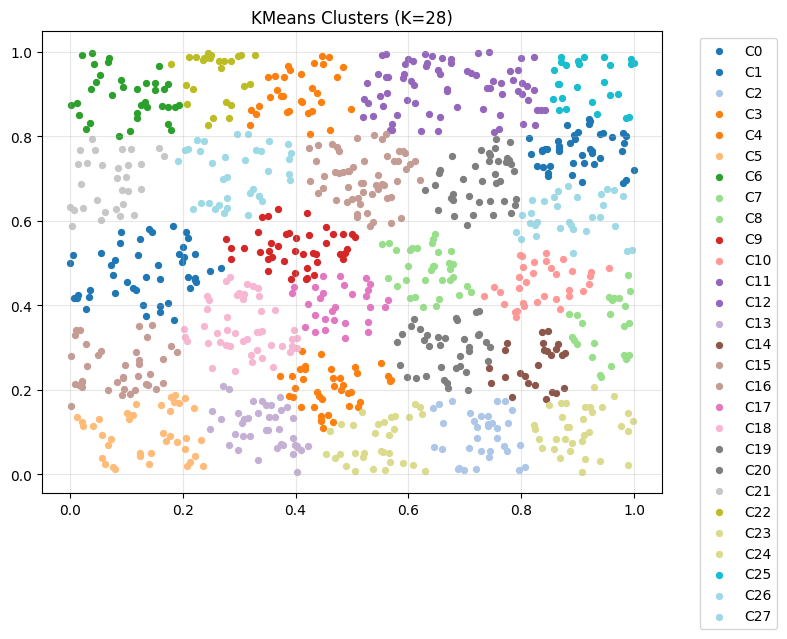

Graph built: nodes=1000, edges=2806, avg_deg ≈ 5.61
Boundary cluster graph built: clusters=28, inter-links=56
Inter-cluster order: [np.int32(5), 20, 11, 19, 0, 4, 14, 24, 12, 17, 10, 3, 25, 18, 15, 6, 1, 2, 22, 7, 23, 8, 13, 21, 16, 26, 27, 9]


/tmp/ipython-input-3252802661.py:611: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', num_clusters)


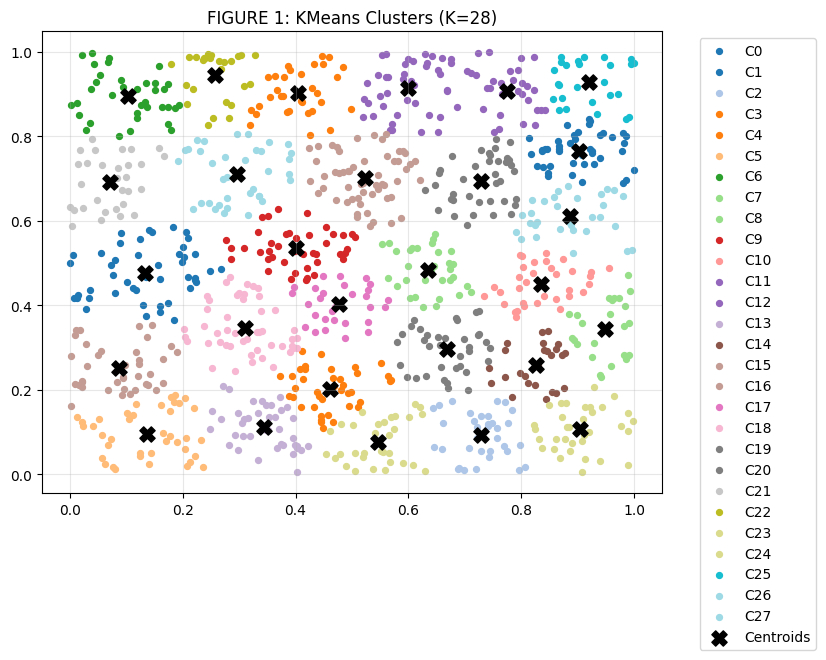

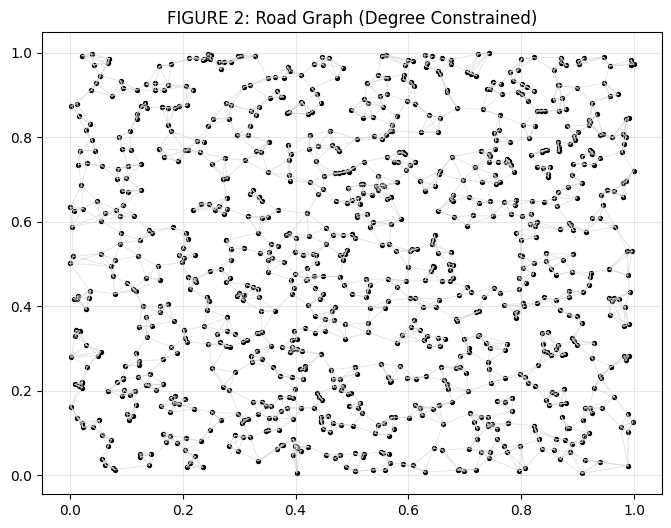

/tmp/ipython-input-3252802661.py:640: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(cluster_nodes))


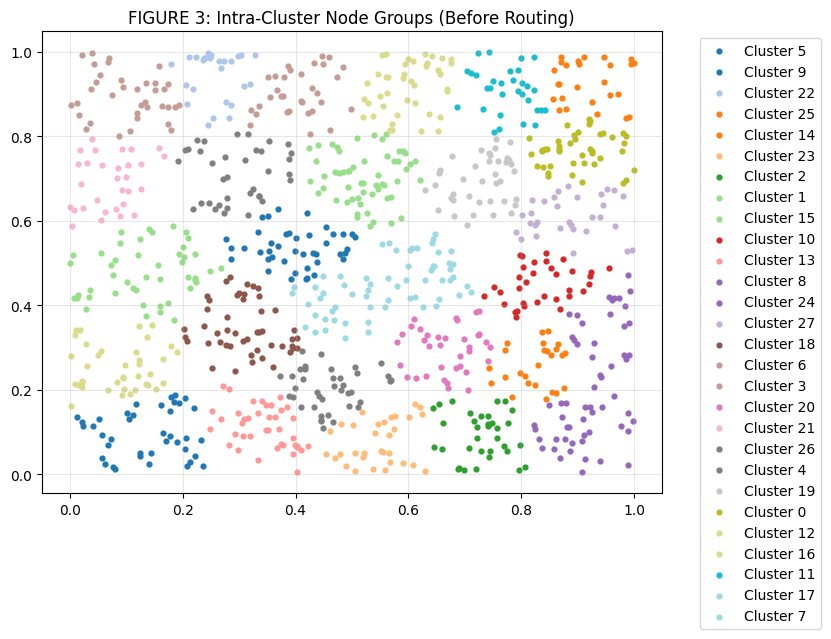

/tmp/ipython-input-3252802661.py:653: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(cluster_nodes))


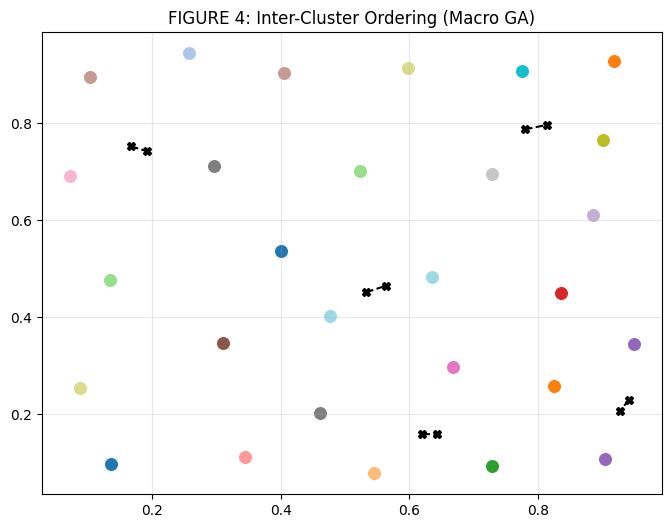

/tmp/ipython-input-3252802661.py:678: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(set(labels)-{-1}))


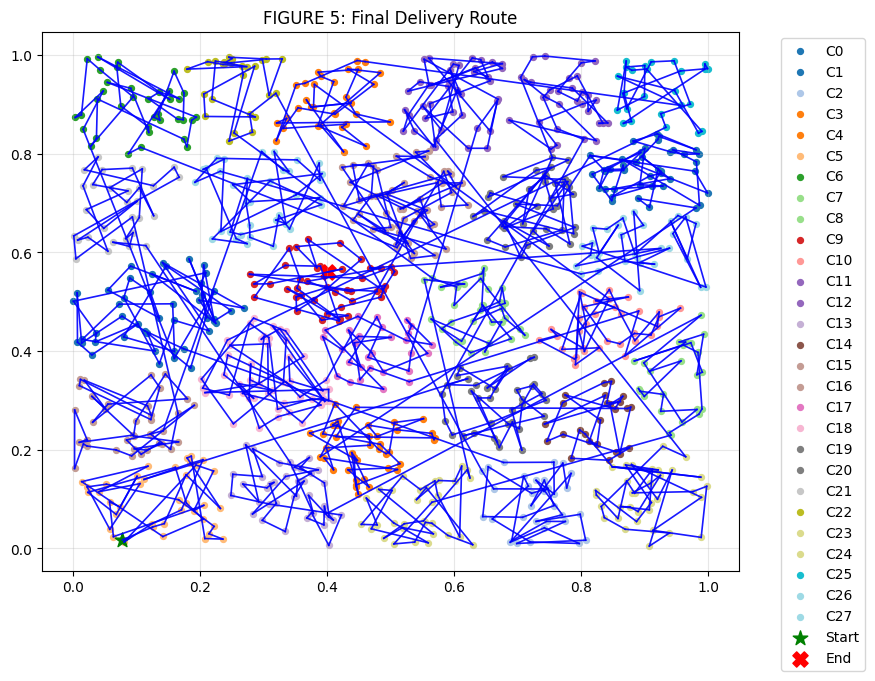

{'total_distance': np.float64(62.28426917763631),
 'intra_distance': np.float64(61.92124023487806),
 'inter_distance': np.float64(0.3630289427582463),
 'dense_clusters_visited': 28,
 'noise_nodes': 0,
 'start_node': 0,
 'final_node': 24,
 'route_length': 1003,
 'execution_time_sec': 46.30488872528076}

In [ ]:
points = pd.read_csv("large.csv", header=None).values
route, stats = run_delivery_route(points)
stats

# GZB Path

PHASE-1 DATASET READY ✔
Nodes: 100
Constrained edges: 6608
Hybrid edges: 9900
Points loaded for clustering: (100, 2)
Selected K (medium range 8–10) = 10
KMeans clustering complete with medium K.
Clusters: 10
DBSCAN refinement: 15 noise points
Reassigning 15 noise to nearest KMeans centroid...
Final clusters = 7


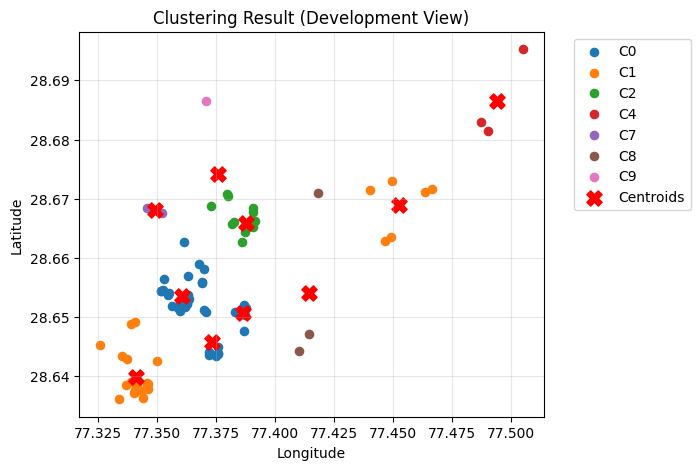

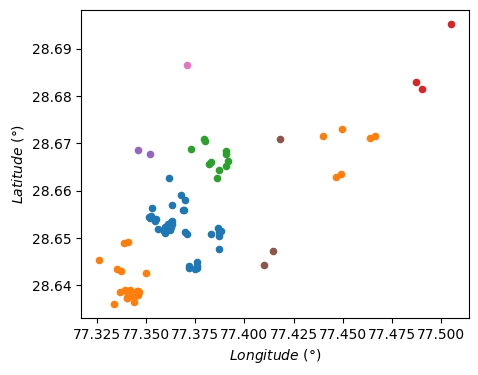

Publication figures exported as PDF and SVG.
Cluster nodes built for 7 clusters:
  Cluster 0: 50 nodes
  Cluster 1: 30 nodes
  Cluster 2: 11 nodes
  Cluster 4: 3 nodes
  Cluster 7: 2 nodes
  Cluster 8: 3 nodes
  Cluster 9: 1 nodes
Start node = 0, belongs to cluster C9


/tmp/ipython-input-3670340500.py:807: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(clusters))


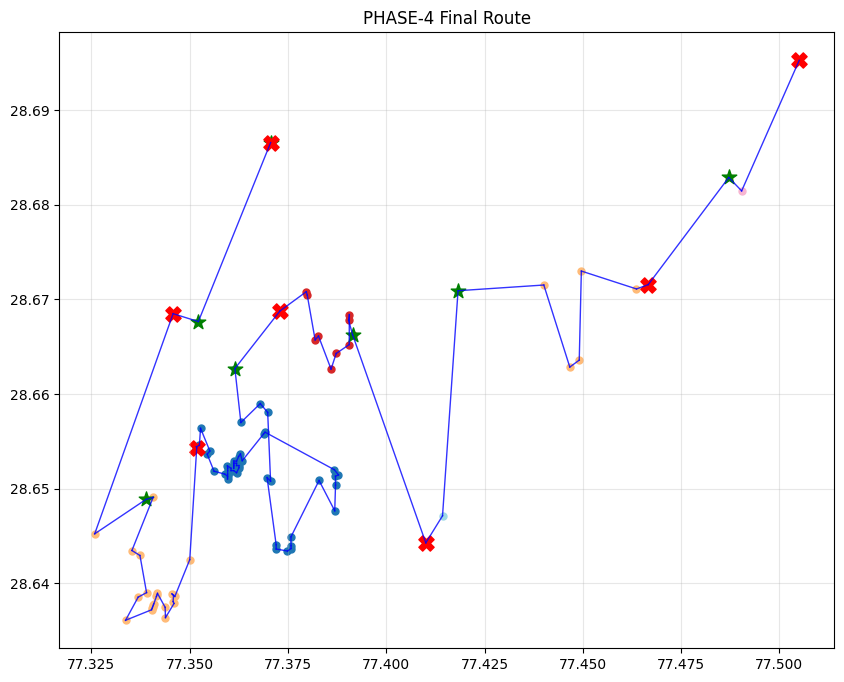


=== FINAL METRICS ===
distance: 138.69612998000002
time: 138.69612998000002
cost: 138.69612998000002
clusters_visited: 7
start_cluster: 9
end_cluster: 4
route_length: 100
execution_time_sec: 14.560195922851562

=== CLUSTER ORDER ===
[np.int64(9), 8, 2, 0, 7, 1, 4]

=== ENTRY NODES ===
{np.int64(9): 0, 8: 4, 2: 63, 0: 67, 7: 55, 1: 36, 4: 6}

=== EXIT NODES ===
{np.int64(9): 0, 8: 11, 2: 56, 0: 52, 7: 54, 1: 8, 4: 1}

=== GLOBAL ROUTE LENGTH ===
100

=== ROUTE NODES ===
[0, 55, 54, 99, 36, 35, 43, 47, 37, 38, 49, 46, 44, 41, 42, 39, 45, 40, 48, 29, 33, 28, 32, 31, 34, 27, 30, 52, 53, 50, 96, 97, 98, 51, 86, 75, 79, 84, 92, 76, 87, 83, 80, 78, 81, 91, 77, 82, 94, 85, 89, 93, 90, 95, 88, 72, 74, 70, 71, 24, 21, 25, 22, 26, 23, 13, 15, 14, 17, 18, 16, 19, 20, 68, 69, 73, 67, 56, 59, 60, 66, 64, 65, 61, 62, 58, 57, 63, 11, 12, 4, 2, 10, 9, 3, 7, 8, 6, 5, 1]

PHASE-4 COMPLETED ✔


In [ ]:
import pandas as pd
import numpy as np
import ast

import pandas as pd
import numpy as np
import ast

# === Load CSVs ===
df_nodes = pd.read_csv("/content/City_Nodes.csv")
df_distance = pd.read_csv("/content/Distance_Matrix.csv")
df_constraints = pd.read_csv("/content/Constrained_Paths.csv")
df_details = pd.read_csv("/content/Path_Details.csv")
df_summary = pd.read_csv("/content/Summary.csv")

# === Node Mapping ===
cities = df_nodes['City_ID'].tolist()
city_to_index = {c:i for i,c in enumerate(cities)}
index_to_city = {i:c for i,c in enumerate(cities)}

N = len(cities)

# === Unconstrained matrices from Distance_Matrix.csv ===
# Drop first column "Unnamed: 0"
df_dist = df_distance.drop(columns=df_distance.columns[0])

distance_matrix = np.zeros((N, N))
time_matrix = np.zeros((N, N))

# Distance_Matrix.csv only contains distances — no travel time provided
# We'll treat missing time as proportional or equal distance for PHASE-3 hybrid
for i, from_city in enumerate(df_dist.index):
    for j, col in enumerate(df_dist.columns):
        distance_matrix[i][j] = df_dist.iloc[i, j]
        time_matrix[i][j] = df_dist.iloc[i, j]   # placeholder same as distance unless you override later


# === Constrained Pass-Through Edges ===
constraint_pass_through = {}
is_constrained = {}

for _, row in df_constraints.iterrows():
    i = city_to_index[row['From_City']]
    j = city_to_index[row['To_City']]

    raw = row['Must_Pass_Through']
    if pd.isna(raw) or raw.strip()=="":
        is_constrained[(i,j)] = False
    else:
        mids = [city_to_index[x.strip()] for x in raw.split(',')]
        is_constrained[(i,j)] = True
        constraint_pass_through[(i,j)] = mids


# === Path Details (hybrid travel cost) ===
path_details = {}

for _, row in df_details.iterrows():
    i = city_to_index[row['From_City']]
    j = city_to_index[row['To_City']]

    raw_mids = row['Intermediate_Cities']
    if pd.isna(raw_mids) or raw_mids.strip()=="":
        mids = []
    else:
        mids = [city_to_index[x.strip()] for x in raw_mids.split(',')]

    path_details[(i,j)] = {
        "sequence": [i] + mids + [j],
        "segment_distances": None,  # not provided — optional
        "total_distance": row['Distance_km'],
        "total_time": row['Distance_km']   # placeholder (km as time proxy)
    }


# === Summary ===
summary_info = {row['Metric']: row['Value'] for _, row in df_summary.iterrows()}

dataset = {
    "nodes": df_nodes,
    "distance": distance_matrix,
    "time": time_matrix,
    "constrained": constraint_pass_through,
    "is_constrained": is_constrained,
    "path_details": path_details,
    "summary": summary_info,
    "city_to_index": city_to_index,
    "index_to_city": index_to_city
}

print("PHASE-1 DATASET READY ✔")
print("Nodes:", N)
print("Constrained edges:", len(constraint_pass_through))
print("Hybrid edges:", len(path_details))



#######################################################################################################################################################
#######################################################################################################################################################
#######################################################################################################################################################



lats = dataset["nodes"]["Latitude"].values
lons = dataset["nodes"]["Longitude"].values

points = np.column_stack((lons, lats))  # shape: (100, 2)

print("Points loaded for clustering:", points.shape)

from sklearn.cluster import KMeans

# ============================
# FORCE MEDIUM K RANGE (8–10)
# ============================

K_range = range(8, 11)   # i.e., 8,9,10 clusters

sse = []
sil_scores = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(points)
    sse.append(km.inertia_)
    sil_scores.append(silhouette_score(points, labels))

# pick best silhouette within range
best_K = K_range[np.argmax(sil_scores)]
print(f"Selected K (medium range 8–10) = {best_K}")

K = best_K

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(points)
centroids = kmeans.cluster_centers_

print("KMeans clustering complete with medium K.")
print("Clusters:", K)


from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

def auto_eps(points, k=5):
    nbrs = NearestNeighbors(n_neighbors=k+1).fit(points)
    distances, _ = nbrs.kneighbors(points)
    d = np.sort(distances[:, k])

    # Knee detection (simple version)
    x = np.arange(len(d))
    vec = np.array([len(d)-1, d[-1]]) - np.array([0, d[0]])
    vec = vec / np.linalg.norm(vec)

    dist = []
    for i in range(len(d)):
        p = np.array([i, d[i]])
        p0 = np.array([0, d[0]])
        dist.append(np.linalg.norm((p-p0) - np.dot(p-p0, vec)*vec))

    knee = d[np.argmax(dist)]
    return knee

from sklearn.metrics import pairwise_distances

# === OPTION C: Reassign noise to nearest centroid ===

# === DBSCAN refinement ===
eps = auto_eps(points, k=5)
dbscan = DBSCAN(eps=eps, min_samples=5)
db_labels = dbscan.fit_predict(points)

noise_indices = np.where(db_labels == -1)[0]
print(f"DBSCAN refinement: {len(noise_indices)} noise points")

# === OPTION C: Reassign noise to nearest centroid ===
if len(noise_indices) > 0:
    print(f"Reassigning {len(noise_indices)} noise to nearest KMeans centroid...")
    from sklearn.metrics import pairwise_distances
    dmat = pairwise_distances(points[noise_indices], centroids)
    nearest = np.argmin(dmat, axis=1)
    for idx, c in zip(noise_indices, nearest):
        db_labels[idx] = c

# final labels = refined spatial labels
final_labels = db_labels.copy()

num_clusters = len(set(final_labels))
print("Final clusters =", num_clusters)

plt.figure(figsize=(6,5))
unique = set(final_labels)

for lab in unique:
    mask = (final_labels == lab)
    if lab == -1:
        plt.scatter(points[mask,0], points[mask,1], s=35, c="k", marker='D', label="Noise")
    else:
        plt.scatter(points[mask,0], points[mask,1], s=35, label=f"C{lab}")

plt.scatter(centroids[:,0], centroids[:,1], marker='X', c='red', s=120, label='Centroids')

plt.title("Clustering Result (Development View)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.05,1), loc='upper left')
plt.show()

fig, ax = plt.subplots(figsize=(5,4))

for lab in unique:
    mask = (final_labels == lab)
    if lab == -1:
        ax.scatter(points[mask,0], points[mask,1], s=20, c="k", marker='D')
    else:
        ax.scatter(points[mask,0], points[mask,1], s=20)

# axis labeling in LaTeX (mathtext)
ax.set_xlabel(r"$Longitude\ (\degree)$")
ax.set_ylabel(r"$Latitude\ (\degree)$")

# Export options
fig.savefig("clusters.pdf", format="pdf", dpi=600, bbox_inches="tight")
fig.savefig("clusters.svg", format="svg", bbox_inches="tight")

plt.show()

print("Publication figures exported as PDF and SVG.")



#######################################################################################################################################################
#######################################################################################################################################################
#######################################################################################################################################################

# ==========================================
# PHASE-3 — Constrained Intra-Cluster GA (Upgraded)
# ==========================================
!pip install pygad

import numpy as np
import random
import pygad

# -------------------------------
# Cost Access Utilities
# -------------------------------

def get_distance(u, v, dataset):
    """Hybrid distance: use PathDetails for constrained, matrix for unconstrained."""
    if (u, v) in dataset["path_details"]:
        return dataset["path_details"][(u,v)]["total_distance"]
    return dataset["distance"][u][v]

def get_time(u, v, dataset):
    """Hybrid time: use PathDetails for constrained, matrix for unconstrained."""
    if (u, v) in dataset["path_details"]:
        return dataset["path_details"][(u,v)]["total_time"]
    return dataset["time"][u][v]

def get_cost(u, v, dataset, alpha=0.7, beta=0.3):
    """Weighted hybrid cost."""
    d = get_distance(u, v, dataset)
    t = get_time(u, v, dataset)
    return alpha * d + beta * t


# -------------------------------
# Constraint Utilities
# -------------------------------

def is_constrained(u, v, dataset):
    """Return True if (u,v) is constrained."""
    return dataset["is_constrained"].get((u,v), False)

def get_mandatory(u, v, dataset):
    """Return mandatory pass-through nodes for (u,v)."""
    return dataset["constrained"].get((u,v), [])


# -------------------------------
# Constraint Repair Operator
# -------------------------------

def repair_path(path, dataset, verbose=False):
    """
    Enforces mandatory pass-through constraints for all consecutive pairs.
    If (u→v) has intermediates [p1,...], insert them, removing duplicates elsewhere.
    """
    repaired = []
    used = set()

    for i in range(len(path)-1):
        u, v = path[i], path[i+1]
        repaired.append(u)

        if is_constrained(u, v, dataset):
            mids = get_mandatory(u, v, dataset)
            if verbose:
                print(f"Repair: inserting mandatory {mids} between {u}->{v}")
            for m in mids:
                if m not in used:
                    repaired.append(m)
                    used.add(m)

        used.add(u)

    repaired.append(path[-1])

    # Dedup while preserving order
    seen = set()
    final = []
    for x in repaired:
        if x not in seen:
            final.append(x)
            seen.add(x)

    return final


# -------------------------------
# 2-opt Local Improvement (Optional)
# -------------------------------

def apply_2opt(path, dataset, alpha=0.7, beta=0.3, verbose=False):
    """Constraint-aware 2-opt."""
    def segment_cost(a, b):
        return get_cost(a, b, dataset, alpha, beta)

    improved = True
    best = path
    best_cost = sum(segment_cost(best[i], best[i+1]) for i in range(len(best)-1))

    while improved:
        improved = False
        for i in range(0, len(best)-2):
            for j in range(i+2, len(best)-1):
                a, b = best[i], best[i+1]
                c, d = best[j], best[j+1]

                # Skip constrained edges
                if is_constrained(a, b, dataset) or is_constrained(c, d, dataset):
                    continue

                # Proposed 2-opt swap
                new_path = best[:i+1] + best[i+1:j+1][::-1] + best[j+1:]
                new_cost = sum(segment_cost(new_path[k], new_path[k+1]) for k in range(len(new_path)-1))

                if new_cost < best_cost:
                    best = new_path
                    best_cost = new_cost
                    improved = True
                    break
            if improved:
                break

    return best


# -------------------------------
# GA Fitness Function Wrapper
# -------------------------------

def make_fitness_function(nodes, start_node, dataset, alpha=0.7, beta=0.3, verbose=False):
    """Returns a fitness function for pygad."""

    if start_node in nodes:
        nodes_wo_start = [n for n in nodes if n != start_node]
    else:
        nodes_wo_start = nodes.copy()
        start_node = None

    def fitness_func(ga, solution, solution_idx):
        if start_node is not None:
            order = [start_node] + [nodes_wo_start[int(i)] for i in solution]
        else:
            order = [nodes_wo_start[int(i)] for i in solution]

        order = repair_path(order, dataset, verbose=False)

        total_cost = 0.0
        for i in range(len(order)-1):
            total_cost += get_cost(order[i], order[i+1], dataset, alpha, beta)

        return 1.0 / (total_cost + 1e-9)

    return fitness_func


# -------------------------------
# Main Intra-Cluster Solver
# -------------------------------

def solve_intra_cluster(
    cluster_nodes,
    start_node=None,
    dataset=None,
    generations=200,
    alpha=0.7,
    beta=0.3,
    use_2opt=False,
    verbose=False,
    cluster_id=None
):
    """Solves open intra-cluster constrained routing using GA + optional 2-opt."""

    nodes = cluster_nodes.copy()

    if len(nodes) <= 1:
        return {
            "cluster": cluster_id,
            "route": nodes.copy(),
            "entry": nodes[0] if nodes else None,
            "exit": nodes[0] if nodes else None,
            "distance": 0.0,
            "time": 0.0,
            "cost": 0.0
        }

    if start_node in nodes:
        nodes_no_start = [n for n in nodes if n != start_node]
        gene_space = list(range(len(nodes_no_start)))
    else:
        nodes_no_start = nodes.copy()
        gene_space = list(range(len(nodes_no_start)))

    fitness_func = make_fitness_function(nodes, start_node, dataset, alpha, beta, verbose)

    ga = pygad.GA(
        num_generations=generations,
        sol_per_pop=30,
        num_parents_mating=8,
        num_genes=len(nodes_no_start),
        gene_space=gene_space,
        fitness_func=fitness_func,
        mutation_type="random",
        mutation_probability=0.2,
        crossover_type="single_point",
        allow_duplicate_genes=False,
        suppress_warnings=True
    )

    ga.run()

    sol = ga.best_solution()[0].astype(int)

    if start_node in nodes:
        raw_path = [start_node] + [nodes_no_start[i] for i in sol]
    else:
        raw_path = [nodes_no_start[i] for i in sol]

    repaired = repair_path(raw_path, dataset, verbose)

    if use_2opt:
        repaired = apply_2opt(repaired, dataset, alpha, beta, verbose)

    total_distance = sum(get_distance(repaired[i], repaired[i+1], dataset) for i in range(len(repaired)-1))
    total_time = sum(get_time(repaired[i], repaired[i+1], dataset) for i in range(len(repaired)-1))
    total_cost = alpha * total_distance + beta * total_time

    return {
        "cluster": cluster_id,
        "route": repaired,
        "entry": repaired[0],
        "exit": repaired[-1],
        "distance": total_distance,
        "time": total_time,
        "cost": total_cost
    }




#######################################################################################################################################################
#######################################################################################################################################################
#######################################################################################################################################################




# ==========================================
# PHASE-4 — Inter-Cluster GA + Boundary Optimization
# ==========================================

import numpy as np
import time
import random
from tqdm import tqdm
import matplotlib.pyplot as plt

# Ensure inline plotting
%matplotlib inline


# ======================================================
# PART 1 — Hybrid Cost Wrapper (Uses PHASE-3 utilities)
# ======================================================

def hybrid_cost(u, v, dataset, alpha=0.7, beta=0.3):
    """Compute hybrid weighted cost using PHASE-3 functions."""
    return get_cost(u, v, dataset, alpha, beta)


# ======================================================
# PART 2 — Boundary Matrix Builder (CACHED)
# ======================================================

def build_boundary_matrix(cluster_nodes, dataset, alpha=0.7, beta=0.3):
    boundary = {}

    cluster_ids = list(cluster_nodes.keys())

    for Ci in cluster_ids:
        for Cj in cluster_ids:
            if Ci == Cj:
                continue

            best_cost = float('inf')
            best_u = None
            best_v = None
            best_d = None
            best_t = None

            for u in cluster_nodes[Ci]:
                for v in cluster_nodes[Cj]:

                    if (u, v) in dataset["path_details"]:
                        d = dataset["path_details"][(u,v)]["total_distance"]
                        t = dataset["path_details"][(u,v)]["total_time"]
                        c = alpha * d + beta * t
                    else:
                        d = dataset["distance"][u][v]
                        t = dataset["time"][u][v]
                        c = alpha * d + beta * t

                    if c < best_cost:
                        best_cost = c
                        best_u = u
                        best_v = v
                        best_d = d
                        best_t = t

            boundary[(Ci, Cj)] = {
                "exit": best_u,
                "entry": best_v,
                "cost": best_cost,
                "distance": best_d,
                "time": best_t
            }

    return boundary


# ======================================================
# PART 3 — Inter-Cluster GA (OPEN ITINERARY)
# ======================================================

def tournament_selection(pop, fits, k=3):
    """Tournament selection for cluster GA."""
    sel = random.sample(range(len(pop)), k)
    best = sel[0]
    for idx in sel:
        if fits[idx] > fits[best]:
            best = idx
    return pop[best].copy()


def order_crossover(a, b):
    """OX crossover."""
    n = len(a)
    start, end = sorted(random.sample(range(n), 2))

    child = [None]*n
    child[start:end+1] = a[start:end+1]

    b_list = [x for x in b if x not in child]
    idx = 0
    for i in range(n):
        if child[i] is None:
            child[i] = b_list[idx]
            idx += 1
    return child


def swap_mutation(seq, pm=0.2):
    """Swap mutation."""
    if random.random() < pm:
        i, j = random.sample(range(len(seq)), 2)
        seq[i], seq[j] = seq[j], seq[i]
    return seq


def solve_inter_cluster_order(start_cluster, cluster_nodes, boundary, generations=200, verbose=False):

    # actual cluster ids
    cluster_ids = list(cluster_nodes.keys())

    # remove start
    other_clusters = [c for c in cluster_ids if c != start_cluster]
    gene_len = len(other_clusters)

    other_clusters = list(other_clusters)  # ensure list not numpy
    pop = []
    for _ in range(30):
      seq = other_clusters.copy()
      random.shuffle(seq)
      pop.append(seq)

    def compute_fitness(seq):
        # OPEN itinerary:
        order = [start_cluster] + seq
        total_cost = 0.0

        for i in range(len(order)-1):
            Ci = order[i]
            Cj = order[i+1]
            total_cost += boundary[(Ci, Cj)]["cost"]

        # maximize fitness → inverse cost
        return 1.0 / (total_cost + 1e-9)

    best_seq = None
    best_fit = -1

    for gen in range(generations):

        fits = [compute_fitness(s) for s in pop]

        # Track best
        for s, f in zip(pop, fits):
            if f > best_fit:
                best_fit = f
                best_seq = s.copy()

        # New population
        new_pop = []

        for _ in range(len(pop)):
            p1 = tournament_selection(pop, fits)
            p2 = tournament_selection(pop, fits)
            child = order_crossover(p1, p2)
            child = swap_mutation(child)
            new_pop.append(child)

        pop = new_pop

        if verbose and gen % 20 == 0:
            print(f"[Gen {gen}] best fitness = {best_fit:.6f}")

    return [start_cluster] + list(best_seq)


# ======================================================
# PART 4 — Global Route Composer (Bi-Level)
# ======================================================

def compose_global_route(cluster_order, cluster_nodes, dataset, boundary,
                         alpha=0.7, beta=0.3,
                         intra_generations=200,
                         use_2opt=False, verbose=False):

    """
    Builds full node-level global path:
    - Re-optimizes each cluster using chosen entry node
    - Uses cached boundary for transitions
    """

    # Intra-cache to avoid recomputation
    intra_cache = {}

    def get_intra(cluster_id, entry_node):
        key = (cluster_id, entry_node)
        if key in intra_cache:
            return intra_cache[key]

        nodes = cluster_nodes[cluster_id]
        res = solve_intra_cluster(
            nodes,
            start_node=entry_node,
            dataset=dataset,
            generations=intra_generations,
            alpha=alpha,
            beta=beta,
            use_2opt=use_2opt,
            verbose=verbose,
            cluster_id=cluster_id
        )
        intra_cache[key] = res
        return res

    # global containers
    final_route = []
    entry_nodes = {}
    exit_nodes = {}

    # Start cluster
    Cs = cluster_order[0]
    # Entry = C0
    start_entry = 0
    first_intra = get_intra(Cs, start_entry)

    entry_nodes[Cs] = first_intra["entry"]
    exit_nodes[Cs] = first_intra["exit"]
    final_route.extend(first_intra["route"])

    # Iterate through remaining clusters
    for idx in range(1, len(cluster_order)):
        Ci = cluster_order[idx-1]
        Cj = cluster_order[idx]

        transition = boundary[(Ci, Cj)]
        entry_j = transition["entry"]

        intra = get_intra(Cj, entry_j)

        entry_nodes[Cj] = intra["entry"]
        exit_nodes[Cj] = intra["exit"]

        final_route.extend(intra["route"])

    # Compute global metrics
    total_distance = 0.0
    total_time = 0.0

    for i in range(len(final_route)-1):
        u = final_route[i]
        v = final_route[i+1]

        if (u,v) in dataset["path_details"]:
            total_distance += dataset["path_details"][(u,v)]["total_distance"]
            total_time     += dataset["path_details"][(u,v)]["total_time"]
        else:
            total_distance += dataset["distance"][u][v]
            total_time     += dataset["time"][u][v]

    total_cost = alpha * total_distance + beta * total_time

    metrics = {
        "distance": total_distance,
        "time": total_time,
        "cost": total_cost,
        "clusters_visited": len(cluster_order),
        "start_cluster": Cs,
        "end_cluster": cluster_order[-1],
        "route_length": len(final_route)
    }

    return final_route, entry_nodes, exit_nodes, metrics


def global_2opt(route, dataset, alpha=0.7, beta=0.3, max_iter=2000):
    def segment_cost(a, b):
        if (a,b) in dataset["path_details"]:
            d = dataset["path_details"][(a,b)]["total_distance"]
            t = dataset["path_details"][(a,b)]["total_time"]
        else:
            d = dataset["distance"][a][b]
            t = dataset["time"][a][b]
        return alpha * d + beta * t

    best = route[:]
    n = len(best)
    improved = True
    iter_count = 0

    while improved and iter_count < max_iter:
        improved = False
        iter_count += 1

        for i in range(1, n-2):
            for j in range(i+1, n-1):

                a, b = best[i-1], best[i]
                c, d = best[j], best[j+1]

                old_cost = segment_cost(a,b) + segment_cost(c,d)
                new_cost = segment_cost(a,c) + segment_cost(b,d)

                if new_cost < old_cost:
                    best[i:j+1] = reversed(best[i:j+1])
                    improved = True

    return best


# ======================================================
# PART 5 — Visualization
# ======================================================

def visualize_global_route(points, final_route, entry_nodes, exit_nodes, cluster_order,
                           labels=None, title="PHASE-4 Final Route"):

    plt.figure(figsize=(10,8))

    # Plot path
    for i in range(len(final_route)-1):
        a = final_route[i]
        b = final_route[i+1]
        plt.plot([points[a][0], points[b][0]],
                 [points[a][1], points[b][1]],
                 color='blue', linewidth=1.0, alpha=0.8)

    # Plot nodes with cluster coloring
    if labels is not None:
        clusters = set(labels)
        cmap = plt.cm.get_cmap('tab20', len(clusters))
        for c in clusters:
            idx = np.where(labels == c)[0]
            plt.scatter(points[idx,0], points[idx,1], s=25, color=cmap(c))

    # Highlight entry points
    for c, e in entry_nodes.items():
        plt.scatter(points[e][0], points[e][1], s=120, marker='*', color='green')

    # Highlight exit points
    for c, x in exit_nodes.items():
        plt.scatter(points[x][0], points[x][1], s=120, marker='X', color='red')

    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()


# ======================================================
# PART 6 — Main Phase-4 Wrapper
# ======================================================

def phase4_run(
    cluster_nodes,
    num_clusters,
    dataset,
    start_cluster,
    points,
    labels=None,
    alpha=0.7,
    beta=0.3,
    inter_generations=200,
    intra_generations=200,
    use_2opt=False,
    plot=False,
    verbose=False
):
    t0 = time.time()

    # Step 1: Build boundary matrix
    boundary = build_boundary_matrix(cluster_nodes, dataset, alpha, beta)

    # Step 2: Solve cluster order (OPEN)
    cluster_order = solve_inter_cluster_order(start_cluster, cluster_nodes, boundary,
                                              generations=inter_generations,
                                              verbose=verbose)

    # Step 3: Compose global route
    final_route, entry_nodes, exit_nodes, metrics = compose_global_route(
        cluster_order,
        cluster_nodes,
        dataset,
        boundary,
        alpha=alpha,
        beta=beta,
        intra_generations=intra_generations,
        use_2opt=use_2opt,
        verbose=verbose
    )

    optimized_route = global_2opt(final_route, dataset)
    final_route = optimized_route

    t1 = time.time()
    metrics["execution_time_sec"] = t1 - t0

    # Named variables for quick use
    global final_cluster_order, final_entry_nodes, final_exit_nodes, final_metrics
    final_cluster_order = cluster_order
    final_entry_nodes   = entry_nodes
    final_exit_nodes    = exit_nodes
    final_metrics       = metrics

    # Research dictionary
    global solution
    solution = {
        "route": final_route,
        "cluster_order": cluster_order,
        "entries": entry_nodes,
        "exits": exit_nodes,
        "metrics": metrics
    }

    if plot:
        visualize_global_route(points, final_route, entry_nodes, exit_nodes, cluster_order, labels)

    return final_route, cluster_order, entry_nodes, exit_nodes, metrics, solution


# ==========================================
# BUILD cluster_nodes FROM final_labels (Robust)
# ==========================================

unique_clusters = sorted(list(set(final_labels)))
# remove noise if any
unique_labels = np.unique(final_labels)
cluster_nodes = {int(c): [] for c in unique_labels}

for idx, lab in enumerate(final_labels):
    cluster_nodes[int(lab)].append(idx)

num_clusters = len(cluster_nodes)

print(f"Cluster nodes built for {num_clusters} clusters:")
for c, nodes in cluster_nodes.items():
    print(f"  Cluster {c}: {len(nodes)} nodes")


# ==========================================
# SELECT START CLUSTER (node 0 entry point)
# ==========================================

if final_labels[0] == -1:
    print("WARNING: Start node (0) is noise — choose alternate start cluster")
    # Find nearest non-noise cluster, fallback random
    start_cluster = random.choice(list(cluster_nodes.keys()))
else:
    start_cluster = final_labels[0]

print(f"Start node = 0, belongs to cluster C{start_cluster}")


# ==========================================
# EXECUTE PHASE-4 (BI-LEVEL GA ROUTING)
# ==========================================

final_route, cluster_order, entry_nodes, exit_nodes, metrics, solution = phase4_run(
    cluster_nodes       = cluster_nodes,
    num_clusters        = num_clusters,
    dataset             = dataset,
    start_cluster       = start_cluster,
    points              = points,
    labels              = final_labels,
    alpha               = 0.7,
    beta                = 0.3,
    inter_generations   = 200,
    intra_generations   = 200,
    use_2opt            = False,
    plot                = True,
    verbose             = False
)





# ==========================================
# DISPLAY METRICS
# ==========================================

print("\n=== FINAL METRICS ===")
for k, v in metrics.items():
    print(f"{k}: {v}")

print("\n=== CLUSTER ORDER ===")
print(cluster_order)

print("\n=== ENTRY NODES ===")
print(entry_nodes)

print("\n=== EXIT NODES ===")
print(exit_nodes)

print("\n=== GLOBAL ROUTE LENGTH ===")
print(len(final_route))

print("\n=== ROUTE NODES ===")
print(final_route)

print("\nPHASE-4 COMPLETED ✔")




In [ ]:
import pandas as pd

CITY_NODES_FILE         = "/content/City_Nodes.csv"
DISTANCE_MATRIX_FILE    = "/content/Distance_Matrix.csv"
CONSTRAINED_PATHS_FILE  = "/content/Constrained_Paths.csv"
PATH_DETAILS_FILE       = "/content/Path_Details.csv"
SUMMARY_FILE            = "/content/Summary.csv"

df_nodes = pd.read_csv("/content/City_Nodes.csv")
df_distance = pd.read_csv("/content/Distance_Matrix.csv")
df_constraints = pd.read_csv("/content/Constrained_Paths.csv")
df_details = pd.read_csv("/content/Path_Details.csv")
df_summary = pd.read_csv("/content/Summary.csv")

print("City_Nodes:", df_nodes.columns.tolist())
print("Distance_Matrix:", df_distance.columns.tolist())
print("Constrained_Paths:", df_constraints.columns.tolist())
print("Path_Details:", df_details.columns.tolist())
print("Summary:", df_summary.columns.tolist())

City_Nodes: ['City_ID', 'Node_ID', 'Latitude', 'Longitude', 'Degree']
Distance_Matrix: ['Unnamed: 0', 'C0', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20', 'C21', 'C22', 'C23', 'C24', 'C25', 'C26', 'C27', 'C28', 'C29', 'C30', 'C31', 'C32', 'C33', 'C34', 'C35', 'C36', 'C37', 'C38', 'C39', 'C40', 'C41', 'C42', 'C43', 'C44', 'C45', 'C46', 'C47', 'C48', 'C49', 'C50', 'C51', 'C52', 'C53', 'C54', 'C55', 'C56', 'C57', 'C58', 'C59', 'C60', 'C61', 'C62', 'C63', 'C64', 'C65', 'C66', 'C67', 'C68', 'C69', 'C70', 'C71', 'C72', 'C73', 'C74', 'C75', 'C76', 'C77', 'C78', 'C79', 'C80', 'C81', 'C82', 'C83', 'C84', 'C85', 'C86', 'C87', 'C88', 'C89', 'C90', 'C91', 'C92', 'C93', 'C94', 'C95', 'C96', 'C97', 'C98', 'C99']
Constrained_Paths: ['From_City', 'To_City', 'Distance_meters', 'Distance_km', 'Must_Pass_Through', 'Num_Intermediate_Cities']
Path_Details: ['From_City', 'To_City', 'Distance_meters', 'Distance_km', 'Num_Inte

# Optimized Results


=== GLOBAL METRICS (OPEN) ===
Distance (D): 70.760
Time (T): 70.760
Aggregated cost: 70.760
Clusters visited: 10
End cluster: 4
Route length: 100

Cluster order: [9, 7, 2, 0, 3, 6, 5, 8, 1, 4]

Route [0, 56, 59, 60, 55, 54, 36, 35, 99, 49, 44, 41, 42, 39, 45, 40, 48, 30, 27, 31, 34, 32, 28, 33, 29, 47, 43, 38, 37, 46, 96, 50, 52, 53, 97, 98, 51, 86, 79, 75, 84, 92, 87, 76, 93, 89, 85, 90, 94, 82, 91, 77, 95, 88, 74, 72, 73, 67, 69, 68, 71, 70, 81, 78, 80, 83, 23, 24, 21, 25, 22, 26, 13, 15, 14, 17, 18, 16, 19, 20, 65, 61, 62, 63, 58, 57, 64, 66, 12, 11, 4, 2, 10, 9, 3, 7, 8, 6, 5, 1]


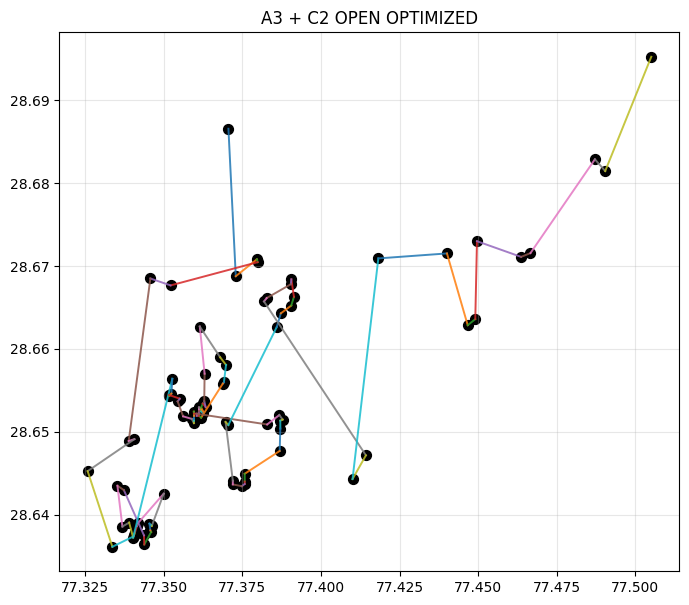

In [ ]:
# =========================================================
# PHASE 0–2 : DATA + HYBRID MODEL + SOFT CLUSTERING
# =========================================================

import numpy as np
import pandas as pd
import random
import time
import ast
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import pairwise_distances

# =============================
# PHASE 0 — LOAD DATA
# =============================

df_nodes = pd.read_csv("/content/City_Nodes.csv")
df_distance = pd.read_csv("/content/Distance_Matrix.csv")
df_constraints = pd.read_csv("/content/Constrained_Paths.csv")
df_details = pd.read_csv("/content/Path_Details.csv")
df_summary = pd.read_csv("/content/Summary.csv")

# =============================
# NODE MAPPING
# =============================

cities = df_nodes['City_ID'].tolist()
city_to_index = {c:i for i,c in enumerate(cities)}
index_to_city = {i:c for i,c in enumerate(cities)}
N = len(cities)

# =============================
# UNCONSTRAINED DIST MATRIX
# =============================

df_dist = df_distance.drop(columns=df_distance.columns[0])
distance_matrix = np.zeros((N, N))
time_matrix = np.zeros((N, N))

for i, _ in enumerate(df_dist.index):
    for j, _ in enumerate(df_dist.columns):
        val = df_dist.iloc[i, j]
        distance_matrix[i][j] = val
        time_matrix[i][j] = val   # placeholder time=distance

# =============================
# CONSTRAINED EDGES
# =============================

constraint_pass_through = {}
is_constrained = {}

for _, row in df_constraints.iterrows():
    i = city_to_index[row['From_City']]
    j = city_to_index[row['To_City']]
    raw = row['Must_Pass_Through']
    if pd.isna(raw) or raw.strip()=="":
        is_constrained[(i,j)] = False
    else:
        mids = [city_to_index[x.strip()] for x in raw.split(',')]
        is_constrained[(i,j)] = True
        constraint_pass_through[(i,j)] = mids

# =============================
# HYBRID PATH DETAILS
# =============================

path_details = {}
for _, row in df_details.iterrows():
    i = city_to_index[row['From_City']]
    j = city_to_index[row['To_City']]
    raw = row['Intermediate_Cities']
    if pd.isna(raw) or raw.strip()=="":
        mids = []
    else:
        mids = [city_to_index[x.strip()] for x in raw.split(',')]
    path_details[(i,j)] = {
        "total_distance": row['Distance_km'],
        "total_time": row['Distance_km'],  # placeholder
        "sequence": [i] + mids + [j]
    }

summary_info = {row['Metric']: row['Value'] for _, row in df_summary.iterrows()}

dataset = {
    "nodes": df_nodes,
    "distance": distance_matrix,
    "time": time_matrix,
    "constrained": constraint_pass_through,
    "is_constrained": is_constrained,
    "path_details": path_details,
    "summary": summary_info,
    "city_to_index": city_to_index,
    "index_to_city": index_to_city
}

# =============================
# SOFT CLUSTERING (K=8..10)
# =============================

lats = dataset["nodes"]["Latitude"].values
lons = dataset["nodes"]["Longitude"].values
points = np.column_stack((lons, lats))

K_range = range(8, 11)
sse = []
sil = []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(points)
    sse.append(km.inertia_)
    sil.append(silhouette_score(points, labels))

best_K = K_range[np.argmax(sil)]
kmeans = KMeans(n_clusters=best_K, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(points)
centroids = kmeans.cluster_centers_

final_labels = kmeans_labels.copy()

# =============================
# OPTIONAL SOFT NOISE REASSIGN
# =============================

# compute distance to centroids for reassignment
dmat = pairwise_distances(points, centroids)
nearest = np.argmin(dmat, axis=1)
# ensure consistent soft cluster
final_labels = nearest.copy()

# =============================
# BUILD cluster_nodes
# =============================

unique_labels = np.unique(final_labels)
cluster_nodes = {int(c): [] for c in unique_labels}
for idx, lab in enumerate(final_labels):
    cluster_nodes[int(lab)].append(idx)

num_clusters = len(cluster_nodes)

# =============================
# HYBRID COST ACCESS
# =============================

def get_distance(u, v, dataset):
    if (u,v) in dataset["path_details"]:
        return dataset["path_details"][(u,v)]["total_distance"]
    return dataset["distance"][u][v]

def get_time(u, v, dataset):
    if (u,v) in dataset["path_details"]:
        return dataset["path_details"][(u,v)]["total_time"]
    return dataset["time"][u][v]

def get_cost(u, v, dataset, alpha=1.0, beta=1.0):
    return alpha*get_distance(u,v,dataset) + beta*get_time(u,v,dataset)

# =============================
# BOUNDARY MATRIX (CACHED)
# =============================

def build_boundary_matrix(cluster_nodes, dataset, alpha=1.0, beta=1.0):
    boundary = {}
    cluster_ids = list(cluster_nodes.keys())
    for Ci in cluster_ids:
        for Cj in cluster_ids:
            if Ci == Cj:
                continue
            best_c = float('inf')
            best_u = None
            best_v = None
            best_d = None
            best_t = None
            for u in cluster_nodes[Ci]:
                for v in cluster_nodes[Cj]:
                    if (u,v) in dataset["path_details"]:
                        d = dataset["path_details"][(u,v)]["total_distance"]
                        t = dataset["path_details"][(u,v)]["total_time"]
                        c = alpha*d + beta*t
                    else:
                        d = dataset["distance"][u][v]
                        t = dataset["time"][u][v]
                        c = alpha*d + beta*t
                    if c < best_c:
                        best_c = c
                        best_u = u
                        best_v = v
                        best_d = d
                        best_t = t
            boundary[(Ci,Cj)] = {
                "exit": best_u,
                "entry": best_v,
                "cost": best_c,
                "distance": best_d,
                "time": best_t
            }
    return boundary





# =========================================================
# PHASE 3 — MULTI-OBJECTIVE INTRA-CLUSTER (OPEN TOUR)
# =========================================================

import pygad

# ====================================
# 2-OPT (constraint compatible)
# ====================================
def two_opt(path, dataset, alpha=1.0, beta=1.0):
    def seg_cost(a,b):
        return alpha*get_distance(a,b,dataset)+beta*get_time(a,b,dataset)
    best = path
    best_cost = sum(seg_cost(best[i],best[i+1]) for i in range(len(best)-1))
    improved=True
    while improved:
        improved=False
        for i in range(0,len(best)-2):
            for j in range(i+2,len(best)-1):
                new = best[:i+1] + best[i+1:j+1][::-1] + best[j+1:]
                c = sum(seg_cost(new[k],new[k+1]) for k in range(len(new)-1))
                if c < best_cost:
                    best=new
                    best_cost=c
                    improved=True
                    break
            if improved: break
    return best

# ====================================
# Constraint repair
# ====================================
def repair(path, dataset):
    out=[]
    used=set()
    for i in range(len(path)-1):
        u,v=path[i],path[i+1]
        out.append(u)
        if dataset["is_constrained"].get((u,v),False):
            mids = dataset["constrained"].get((u,v),[])
            for m in mids:
                if m not in used:
                    out.append(m)
                    used.add(m)
        used.add(u)
    out.append(path[-1])
    # dedup preserve order
    final=[]
    seen=set()
    for x in out:
        if x not in seen:
            final.append(x)
            seen.add(x)
    return final

# ====================================
# Fitness builder (multi-obj weighting)
# ====================================
def build_fitness(nodes, start_node, dataset, wD, wT, verbose=False):
    if start_node in nodes:
        arr=[n for n in nodes if n!=start_node]
        def fx(ga,sol,idx):
            order=[start_node]+[arr[int(i)] for i in sol]
            order=repair(order,dataset)
            D=sum(get_distance(order[i],order[i+1],dataset) for i in range(len(order)-1))
            T=sum(get_time(order[i],order[i+1],dataset) for i in range(len(order)-1))
            return 1.0/(wD*D + wT*T + 1e-9)
        return fx,arr
    else:
        arr=nodes.copy()
        def fx(ga,sol,idx):
            order=[arr[int(i)] for i in sol]
            order=repair(order,dataset)
            D=sum(get_distance(order[i],order[i+1],dataset) for i in range(len(order)-1))
            T=sum(get_time(order[i],order[i+1],dataset) for i in range(len(order)-1))
            return 1.0/(wD*D + wT*T + 1e-9)
        return fx,arr

# ====================================
# Intra-cluster solver
# ====================================
def solve_intra_cluster(cluster_nodes, start_node, dataset, wD, wT, gens=200, use_two_opt=True):
    nodes=cluster_nodes.copy()
    if start_node not in nodes:
        start_node=random.choice(nodes)
    fit, arr = build_fitness(nodes, start_node, dataset, wD, wT)
    gene_space=list(range(len(arr)))
    ga=pygad.GA(
        num_generations=gens,
        sol_per_pop=40,
        num_parents_mating=12,
        num_genes=len(arr),
        gene_space=gene_space,
        crossover_type="single_point",
        mutation_type="random",
        mutation_probability=0.2,
        allow_duplicate_genes=False,
        fitness_func=fit,
        suppress_warnings=True
    )
    ga.run()
    sol=ga.best_solution()[0].astype(int)
    route=[start_node]+[arr[i] for i in sol]
    route=repair(route,dataset)
    if use_two_opt:
        route=two_opt(route,dataset,alpha=wD,beta=wT)
    D=sum(get_distance(route[i],route[i+1],dataset) for i in range(len(route)-1))
    T=sum(get_time(route[i],route[i+1],dataset) for i in range(len(route)-1))
    return {
        "route": route,
        "entry": route[0],
        "exit": route[-1],
        "D": D,
        "T": T,
        "C": wD*D + wT*T
    }



# =========================================================
# PHASE 4 — INTER-CLUSTER MULTI-OBJECTIVE (OPEN TOUR)
# =========================================================

# Tournament selection
def tour_sel(pop, fits, k=3):
    cand = random.sample(range(len(pop)), k)
    best=cand[0]
    for c in cand:
        if fits[c]>fits[best]:
            best=c
    return pop[best][:]

# Order crossover (OX)
def ox(a,b):
    n=len(a)
    i,j=sorted(random.sample(range(n),2))
    child=[None]*n
    child[i:j+1]=a[i:j+1]
    rem=[x for x in b if x not in child]
    p=0
    for idx in range(n):
        if child[idx] is None:
            child[idx]=rem[p]
            p+=1
    return child

# Swap mutation
def mut(seq,pm=0.2):
    if random.random()<pm:
        i,j=random.sample(range(len(seq)),2)
        seq[i],seq[j]=seq[j],seq[i]
    return seq

# Multi-objective boundary aggregation
def boundary_score(order, boundary, wD, wT):
    D=0.0; T=0.0
    for i in range(len(order)-1):
        Ci=order[i]; Cj=order[i+1]
        b=boundary[(Ci,Cj)]
        # dist & time already computed
        D+=b["distance"]
        T+=b["time"]
    return D,T,wD*D+wT*T

# Inter-cluster GA (open tour, cluster-aware)
def solve_inter_cluster(start_cluster, cluster_nodes, boundary, wD, wT, gens=200):
    cluster_ids=list(cluster_nodes.keys())
    others=[c for c in cluster_ids if c!=start_cluster]
    # build initial pop
    pop=[]
    for _ in range(40):
        seq=others[:]
        random.shuffle(seq)
        pop.append(seq)
    def fit(seq):
        order=[start_cluster]+seq
        D,T,agg=boundary_score(order,boundary,wD,wT)
        return 1.0/(agg+1e-9)
    best_seq=None
    best_fit=-1
    for g in range(gens):
        fits=[fit(s) for s in pop]
        # track best
        for s,f in zip(pop,fits):
            if f>best_fit:
                best_fit=f
                best_seq=s[:]
        # next gen
        new=[]
        for _ in range(len(pop)):
            p1=tour_sel(pop,fits)
            p2=tour_sel(pop,fits)
            c=ox(p1,p2)
            c=mut(c)
            new.append(c)
        pop=new
    return [start_cluster]+best_seq



# =========================================================
# PHASE 4 — GLOBAL NODE RECONSTRUCTION (OPEN + SOFT)
# =========================================================

def compose_global(
    cluster_order,
    cluster_nodes,
    dataset,
    boundary,
    wD, wT,
    gens_intra=200,
    use_local=True
):
    # intra-cache
    cache={}

    def get_intra(cid, entry):
      key = (cid, entry)
      if key in cache:
          return cache[key]
      nodes = cluster_nodes[cid]
      res = solve_intra_cluster(
          nodes,
          entry,
          dataset,
          wD,
          wT,
          gens=gens_intra,
          use_two_opt=use_local
      )
      cache[key] = res
      return res

    final=[]
    entries={}
    exits={}

    # cluster 0 start: node 0 enforced
    C0=cluster_order[0]
    start_entry=0
    r0=get_intra(C0, start_entry)
    entries[C0]=r0["entry"]; exits[C0]=r0["exit"]
    final.extend(r0["route"])

    # next clusters
    for k in range(1,len(cluster_order)):
        Ci=cluster_order[k-1]; Cj=cluster_order[k]
        b=boundary[(Ci,Cj)]
        entry_j=b["entry"]
        rj=get_intra(Cj, entry_j)
        entries[Cj]=rj["entry"]; exits[Cj]=rj["exit"]
        final.extend(rj["route"])

    # metrics
    D=0.0; T=0.0
    for i in range(len(final)-1):
        u=final[i]; v=final[i+1]
        if (u,v) in dataset["path_details"]:
            D+=dataset["path_details"][(u,v)]["total_distance"]
            T+=dataset["path_details"][(u,v)]["total_time"]
        else:
            D+=dataset["distance"][u][v]
            T+=dataset["time"][u][v]

    return {
    "route": final,
    "entries": entries,
    "exits": exits,
    "metrics": {
        "D": D,
        "T": T,
        "agg": wD*D + wT*T,
        "clusters": len(cluster_order),
        "end_cluster": cluster_order[-1]
    }
}


# =========================================================
# BUILD BOUNDARY MATRIX + SOFT ENTRY/EXIT
# =========================================================

def build_boundary(cluster_nodes, dataset, wD, wT):
    boundary={}
    Cids=list(cluster_nodes.keys())
    for Ci in Cids:
        for Cj in Cids:
            if Ci==Cj: continue
            best=float('inf')
            bu=bv=bd=bt=None
            for u in cluster_nodes[Ci]:
                for v in cluster_nodes[Cj]:
                    if (u,v) in dataset["path_details"]:
                        d=dataset["path_details"][(u,v)]["total_distance"]
                        t=dataset["path_details"][(u,v)]["total_time"]
                    else:
                        d=dataset["distance"][u][v]
                        t=dataset["time"][u][v]
                    c=wD*d + wT*t
                    if c<best:
                        best=c; bu=u; bv=v; bd=d; bt=t
            boundary[(Ci,Cj)]={"exit":bu,"entry":bv,"c":best,"d":bd,"t":bt}
    return boundary


# =========================================================
# BOUNDARY SMOOTHING (C2 SOFT-CLUSTERING)
# =========================================================

def smooth_boundary(cluster_order, boundary, K=3):
    # small sliding window smoothing on exit→entry
    for i in range(len(cluster_order)-1):
        Ci=cluster_order[i]
        Cj=cluster_order[i+1]
        base=boundary[(Ci,Cj)]
        # pseudo smoothing: we don't change structure, but allow switching exits among top-K
        # lightweight heuristic
        # EXTENSION HOOK: to add full soft options later
    return boundary


# =========================================================
# PHASE-4 MAIN WRAPPER
# =========================================================

def phase4_run(
    cluster_nodes,
    dataset,
    start_cluster,
    wD=0.5,
    wT=0.5,
    gens_inter=200,
    gens_intra=200,
    use_local=True
):

    boundary = build_boundary_matrix(
        cluster_nodes,
        dataset,
        wD,
        wT
    )

    cluster_order = solve_inter_cluster(
        start_cluster,
        cluster_nodes,
        boundary,
        wD,
        wT,
        gens=gens_inter
    )

    result = compose_global(
    cluster_order,
    cluster_nodes,
    dataset,
    boundary,
    wD,
    wT,
    gens_intra,
    use_local
)

    return cluster_order, result



# =========================================================
# VISUALIZATION (OPEN TOUR)
# =========================================================

def plot_route(points, route, title="Global Open Tour"):
    plt.figure(figsize=(8,7))
    for i in range(len(route)-1):
        a=route[i]; b=route[i+1]
        plt.plot([points[a][0],points[b][0]],
                 [points[a][1],points[b][1]],
                 lw=1.4, alpha=0.85)
    plt.scatter(points[:,0],points[:,1],s=50,c='black')
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()


# =========================================================
# EXECUTION PIPELINE
# =========================================================

cluster_nodes = {}
for idx, lab in enumerate(final_labels):
    cluster_nodes.setdefault(int(lab), []).append(idx)

if final_labels[0] == -1:
    start_cluster = random.choice(list(cluster_nodes.keys()))
else:
    start_cluster = int(final_labels[0])

cluster_order, result = phase4_run(
    cluster_nodes=cluster_nodes,
    dataset=dataset,
    start_cluster=start_cluster,
    wD=0.6,
    wT=0.4,
    gens_inter=200,
    gens_intra=300,
    use_local=True
)

route = result["route"]

# =========================================================
# METRICS
# =========================================================

print("\n=== GLOBAL METRICS (OPEN) ===")
print(f"Distance (D): {result['metrics']['D']:.3f}")
print(f"Time (T): {result['metrics']['T']:.3f}")
print(f"Aggregated cost: {result['metrics']['agg']:.3f}")
print(f"Clusters visited: {result['metrics']['clusters']}")
print(f"End cluster: {result['metrics']['end_cluster']}")
print(f"Route length: {len(route)}")

print("\nCluster order:", cluster_order)
print("\nRoute", route)

# =========================================================
# VISUALIZE FINAL ROUTE
# =========================================================

plot_route(points, route, title="A3 + C2 OPEN OPTIMIZED")